<a href="https://colab.research.google.com/github/revak18/science_fair_2026/blob/main/science_fair_2026_DRAFT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# @title 1. SETUP & CONFIGURATION
# ==========================================
# 1. SETUP & CONFIGURATION
# ==========================================
import os
import sys
import shutil
import zipfile
import requests
import numpy as np
import pandas as pd
import pulp
import matplotlib.pyplot as plt
from datetime import timedelta
from google.colab import drive

# Mount Drive
drive.mount("/content/drive")

# Configuration
BASE_DIR = "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
HOURLY_LOAD_DIR = os.path.join(BASE_DIR, "hourly_load_raw")
WATER_IMPACT_DIR = os.path.join(BASE_DIR, "water_impact_raw")
RESULTS_FILE = "final_scientific_results_optimized.csv"

# Make directories
for d in [BASE_DIR, HOURLY_LOAD_DIR, WATER_IMPACT_DIR]:
    os.makedirs(d, exist_ok=True)

# Simulation Settings
REGIONS = ["PJME", "COMED", "AEP", "DAYTON", "DOM"] # Grid Sub-regions to study
AI_LOAD_LEVELS = [0.10, 0.20, 0.30]
HORIZON_HOURS = 48

# --- UPDATED SETTINGS FOR ROBUSTNESS ---
N_TRIALS = 50          # CHANGED: Increased from 1 to 50 for statistical robustness
DROUGHT_FACTOR = 1.0   # Set to 1.2 or 1.5 to simulate drought
PLANT_SIZE_MW = 500.0  # For the "Power Plant Equivalent" chart

# --- NEW: PARETO FRONTIER WEIGHTS ---
# Weights for water penalty in objective: Minimize C_gas + (weight * W_peak)
# 0.0 = Pure Gas Optimization, 0.001 = Balanced, 0.1 = Water Conservative
PARETO_WEIGHTS = [0.0, 0.001, 0.1]

# Kaggle Credentials (Update if needed, or rely on manual upload)
os.environ['KAGGLE_USERNAME'] = "revakaggle"
os.environ['KAGGLE_KEY'] = "KGAT_ed225b90e0bddb93c8beeb022b1a9d88"

print(f"Setup Complete. Data Directory: {BASE_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup Complete. Data Directory: /content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data


In [ ]:
# @title 2. DATA DOWNLOADERS (Run Once)
# ==========================================
# 2. DATA DOWNLOADERS (Run Once)
# ==========================================
def download_data_if_missing():
    # A. Grid Load (Kaggle)
    if not os.listdir(HOURLY_LOAD_DIR):
        print("Downloading Grid Load Data from Kaggle...")
        os.system(f'kaggle datasets download -d robikscube/hourly-energy-consumption -p "{BASE_DIR}"')
        zip_path = os.path.join(BASE_DIR, "hourly-energy-consumption.zip")
        with zipfile.ZipFile(zip_path, 'r') as z:
            z.extractall(HOURLY_LOAD_DIR)
        print("Grid Data Extracted.")

    # B. Water Data (HydroShare)
    # Direct URL to the specific csv to save time (skipping the 1.3GB bag if possible)
    # If full bag is needed, use your original code. Here we assume the CSV exists or we download the bag.
    water_csv_name = "Water_IMPACT-Data_Consumption_2020.csv"
    water_csv_path = os.path.join(BASE_DIR, water_csv_name)

    if not os.path.exists(water_csv_path):
        print("Downloading Water IMPACT Data...")
        # (This is the URL for the full bag, uncomment if needed)
        # url = "https://www.hydroshare.org/hsapi/resource/2f54448714554f83b9655da108f0fd3f/"
        # For now, we assume you have placed the CSV in the folder as per previous logs.
        # If not, upload it manually to Drive.
        pass

download_data_if_missing()

Grid Data Extracted.


In [ ]:
# @title 3. DATA LOADERS
# ==========================================
# 3. DATA LOADERS
# ==========================================

def load_ba_load(region: str):
    """Loads Grid Load, handles duplicates, standardizes columns."""
    print(f"   -> Loading Grid Load for {region}...")
    fname = f"{region}_hourly.csv"
    path = os.path.join(HOURLY_LOAD_DIR, fname)

    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

    # Load & Parse
    df = pd.read_csv(path, parse_dates=["Datetime"])

    # Rename value column to 'load_MW'
    mw_col = [c for c in df.columns if c.endswith("_MW")][0]
    df = df.rename(columns={mw_col: "load_MW"})

    # Index & De-duplicate (Fixes "cannot reindex" error)
    df = df.set_index("Datetime").sort_index()
    df = df.groupby(df.index).mean(numeric_only=True)

    return df

def load_water_intensity(region: str):
    """Loads Water Data, Maps Sub-regions (PJME->PJM), Fixes Text/Numeric Errors."""
    print(f"   -> Loading Water Intensity for {region}...")

    # --- SMART MAPPING ---
    REGION_MAP = {
        "PJME": "PJM", "PJMW": "PJM", "COMED": "PJM", "DAYTON": "PJM",
        "AEP": "PJM", "DOM": "PJM", "DUQ": "PJM", "FE": "PJM",
        "DEOK": "PJM", "NI": "PJM", "PJM": "PJM",
        "CISO": "CISO", "ERCOT": "ERCO", "SPP": "SWPP"
    }
    search_region = REGION_MAP.get(region, region)

    path = os.path.join(BASE_DIR, "Water_IMPACT-Data_Consumption_2020.csv")
    if not os.path.exists(path):
        # Fallback to searching raw folder
        path = os.path.join(WATER_IMPACT_DIR, "Water_IMPACT-Data_Consumption_2020.csv")

    df = pd.read_csv(path, parse_dates=["date"])

    # Filter by Region
    col = "balancing_authority" if "balancing_authority" in df.columns else "ba_code"
    df = df[df[col] == search_region].copy()

    if df.empty:
        raise ValueError(f"Region '{search_region}' not found in Water Data.")

    # Index & De-duplicate (Fixes TypeError: string to numeric)
    df = df.set_index("date").sort_index()
    df = df.groupby(df.index).mean(numeric_only=True)

    # Select Consumption Column
    target = "wci_primary" if "wci_primary" in df.columns else "w_consume_l_per_kwh"
    df["w_m3_per_MWh"] = pd.to_numeric(df[target], errors="coerce") * DROUGHT_FACTOR

    # Resample to Hourly & Fill Gaps
    df_clean = df[["w_m3_per_MWh"]].resample("h").mean()
    df_clean = df_clean.interpolate(limit=3).ffill().bfill()

    return df_clean

def build_stressed_window(load_df, water_df, horizon_hours):
    """Aligns Historical Peak Load (e.g., 2015) with Water Data (2020)."""
    print("   -> Extracting Peak Window...")

    # 1. Find Historical Peak
    rolling = load_df["load_MW"].rolling(window=24*7, min_periods=24).mean()
    peak_time = rolling.idxmax()

    # 2. Extract Window
    half = timedelta(hours=horizon_hours // 2)
    start = peak_time - half
    end = start + timedelta(hours=horizon_hours - 1)

    # 3. Time Shift Logic (Project to Water Year)
    target_year = water_df.index.year[0] # Detects 2020

    # extract slice
    load_slice = load_df.loc[start:end].copy()

    # Shift index to target year
    new_dates = []
    for d in load_slice.index:
        try:
            new_d = d.replace(year=target_year)
        except ValueError: # Leap year fix
            new_d = d.replace(year=target_year, month=3, day=1)
        new_dates.append(new_d)

    load_slice.index = pd.DatetimeIndex(new_dates)

    # 4. Merge
    window_df = pd.DataFrame(index=load_slice.index)
    window_df["L_base_MW"] = load_slice["load_MW"]
    window_df["water_m3_per_mwh"] = water_df["w_m3_per_MWh"].reindex(window_df.index)

    # Fill remaining gaps from reindexing
    window_df = window_df.interpolate(limit=3).ffill().bfill()

    return window_df

In [ ]:
# @title 4. WORKLOAD GENERATION & SOLVER
import numpy as np
import pulp

# --- 1. WORKLOAD GENERATORS (Unchanged) ---
def build_online_ai_load(window_df, L_max, fraction, rng):
    base = fraction * L_max
    L_online = np.zeros(len(window_df))
    for t, ts in enumerate(window_df.index):
        # Diurnal pattern: Higher during day (9am-9pm)
        mult = 1.3 if 9 <= ts.hour <= 21 else 0.4
        noise = rng.uniform(0.9, 1.1)
        L_online[t] = base * mult * noise
    return L_online

def generate_jobs(T, t_peak, L_max, rng):
    # Simplified Job Generator
    jobs = []
    # Mix of small, medium, large jobs
    configs = [("small", 10, 0.02, 4), ("medium", 5, 0.05, 8), ("large", 2, 0.08, 12)]

    for name, count, p_frac, d_base in configs:
        for _ in range(count):
            p = rng.uniform(p_frac*0.8, p_frac*1.2) * L_max
            dur = int(rng.integers(d_base-2, d_base+3))
            # Release near peak
            r_center = max(0, t_peak - 4)
            r = int(rng.integers(max(0, r_center-10), min(T, r_center+10)))
            deadline = min(T, r + dur + 12) # 12h slack
            jobs.append({"power": p, "duration": dur, "release": r, "deadline": deadline})
    return jobs

# --- 2. SOLVER (Enhanced for Pareto & Traces) ---
# =========================================================
# CHANGE: Added water_weight parameter for Multi-Objective Analysis
# =========================================================
# def solve_milp(L_base, L_online, jobs, w_vec, alpha=0.3, rho=0.15): # OLD
def solve_milp(L_base, L_online, jobs, w_vec, alpha=0.3, rho=0.15, water_weight=0.001): # NEW
    T = len(L_base)
    L_max = L_base.max()
    C_non = np.full(T, (1.0 - alpha) * L_max)

    prob = pulp.LpProblem("Flex", pulp.LpMinimize)

    # Vars
    C_gas = pulp.LpVariable("C_gas", 0)
    W_peak = pulp.LpVariable("W_peak", 0)

    # Job Vars: x[j,t] = 1 if job j is active at time t
    x = {}
    y = {} # Start vars

    for j, job in enumerate(jobs):
        for t in range(T):
            x[j,t] = pulp.LpVariable(f"x_{j}_{t}", 0, 1, pulp.LpBinary)
            y[j,t] = pulp.LpVariable(f"y_{j}_{t}", 0, 1, pulp.LpBinary)

    # =========================================================
    # CHANGE: Use dynamic weight for Pareto Frontier exploration
    # =========================================================
    # Objective: Minimize Capacity + weighted Water penalty
    # prob += C_gas + 0.001 * W_peak # OLD
    prob += C_gas + (water_weight * W_peak) # NEW

    # Constraints
    for j, job in enumerate(jobs):
        d, r, D = job["duration"], job["release"], job["deadline"]

        # 1. Single Start
        valid_starts = range(r, D - d + 1)
        if len(valid_starts) > 0:
            prob += pulp.lpSum(y[j,t] for t in valid_starts) == 1

        # 2. Contiguity (x is sum of recent y's)
        for t in range(T):
            # Sum of starts in window [t-d+1, t]
            recent_starts = [y[j,k] for k in range(max(0, t-d+1), t+1) if k in valid_starts]
            prob += x[j,t] == pulp.lpSum(recent_starts)

    # System Constraints
    for t in range(T):
        L_batch = pulp.lpSum(jobs[j]["power"] * x[j,t] for j in range(len(jobs)))
        L_total = (1+rho)*L_base[t] + L_online[t] + L_batch

        # Adequacy
        prob += L_total <= C_non[t] + C_gas

        # Water Peak
        prob += W_peak >= w_vec[t] * L_total

    # Solve
    prob.solve(pulp.PULP_CBC_CMD(msg=False))

    # Returns Full Traces (Dictionary)
    if prob.status == 1: # Optimal
        # 1. Reconstruct the Hourly Optimized Batch Load
        L_batch_opt = np.zeros(T)
        for t in range(T):
            # Sum power of all active jobs at time t
            L_batch_opt[t] = sum(jobs[j]["power"] * pulp.value(x[j,t]) for j in range(len(jobs)))

        # 2. Recompute System Traces
        L_total_opt = (1+rho)*L_base + L_online + L_batch_opt
        g_gas_opt = np.maximum(0, L_total_opt - C_non)
        w_rate_opt = w_vec * L_total_opt

        return {
            "status": "Optimal",
            "C_peak": pulp.value(C_gas),
            "W_peak": pulp.value(W_peak),
            "L_batch": L_batch_opt,
            "L_total": L_total_opt,
            "g_gas": g_gas_opt,
            "w_rate": w_rate_opt
        }
    else:
        return {"status": "Infeasible"}

In [ ]:
# @title 5. MAIN EXECUTION LOOP
# ==========================================
# 5. MAIN EXECUTION LOOP
# ==========================================
print("\n=== STARTING MULTI-REGION STUDY ===")
results = []
all_traces = [] # Storage for full time-series data

for region in REGIONS:
    print(f"\nProcessing Region: {region}...")
    try:
        # 1. Load Data
        load_df = load_ba_load(region)
        water_df = load_water_intensity(region)

        # 2. Build Window
        window = build_stressed_window(load_df, water_df, HORIZON_HOURS)
        L_base = window["L_base_MW"].values
        w_vec = window["water_m3_per_mwh"].values
        T = len(L_base)
        L_max = L_base.max()

        # Identify Peak Index for job clustering
        base_total = (1 + 0.15) * L_base
        t_peak = np.argmax(base_total)

        # 3. Run Scenarios
        for ai_frac in AI_LOAD_LEVELS:
            print(f"   -> AI Level: {ai_frac:.2f}")

            # =========================================================
            # NEW: Pareto Frontier Loop (Gas vs. Water Trade-offs)
            # =========================================================
            for w_weight in PARETO_WEIGHTS:
                # Optional: print(f"      -> Weight: {w_weight}")

                for trial in range(N_TRIALS):
                    rng = np.random.default_rng(trial)

                    # Create Workload
                    L_online = build_online_ai_load(window, L_max, ai_frac, rng)
                    jobs = generate_jobs(T, t_peak, L_max, rng)

                    # =========================================================
                    # A. COMPUTE TRUE BASELINE (Naive)
                    # =========================================================
                    # 1. Reconstruct Naive Batch Profile (Jobs run ASAP at release)
                    L_naive_batch = np.zeros(T)
                    for job in jobs:
                        start_t = job["release"]
                        end_t = min(start_t + job["duration"], T)
                        L_naive_batch[start_t : end_t] += job["power"]

                    # 2. Calculate Total System Load (Naive)
                    L_total_naive = (1.15 * L_base) + L_online + L_naive_batch

                    # 3. Calculate "Before" Metrics
                    C_non_gas = (1.0 - 0.3) * L_max
                    # Gas Dispatch Trace (Naive)
                    g_base_trace = np.maximum(0, L_total_naive - C_non_gas)
                    c_base = max(0, np.max(g_base_trace))

                    # Water Peak (Naive)
                    w_base_trace = w_vec * L_total_naive
                    w_base = np.max(w_base_trace)

                    # =========================================================
                    # B. RUN OPTIMIZER (With Dynamic Weight)
                    # =========================================================
                    # We pass the Pareto weight to the solver here
                    sol = solve_milp(L_base, L_online, jobs, w_vec, water_weight=w_weight)

                    if sol["status"] == "Optimal":
                        # Calculate Headline Impact Metrics
                        avoided_mw = c_base - sol["C_peak"]
                        water_saved_abs = w_base - sol["W_peak"]

                        # 1. Extract Scalar Metrics for Summary CSV
                        results.append({
                            "region": region,
                            "ai_fraction": ai_frac,
                            "trial": trial,
                            "water_weight": w_weight, # Track the trade-off setting

                            # Standard Metrics
                            "avoided_capacity_mw": avoided_mw,
                            "water_peak_m3h": sol["W_peak"],
                            "baseline_capacity_mw": c_base,
                            "baseline_water_m3h": w_base,

                            # NEW: Headline Impact Metrics
                            "plants_avoided": avoided_mw / PLANT_SIZE_MW,
                            "peak_reduction_pct": (avoided_mw / c_base * 100) if c_base > 0 else 0,
                            "water_saved_absolute": water_saved_abs
                        })

                        # 2. Extract Full Traces for "Mechanism" Plots
                        for t in range(T):
                            all_traces.append({
                                "region": region,
                                "ai_fraction": ai_frac,
                                "trial": trial,
                                "water_weight": w_weight, # Important for filtering traces later
                                "hour": t,
                                # Inputs
                                "L_grid": L_base[t],
                                "L_online": L_online[t],
                                "water_intensity": w_vec[t],
                                # Baseline Traces
                                "L_batch_base": L_naive_batch[t],
                                "L_total_base": L_total_naive[t],
                                "g_gas_base": g_base_trace[t],
                                "w_rate_base": w_base_trace[t],
                                # Optimized Traces
                                "L_batch_opt": sol["L_batch"][t],
                                "L_total_opt": sol["L_total"][t],
                                "g_gas_opt": sol["g_gas"][t],
                                "w_rate_opt": sol["w_rate"][t]
                            })
                    else:
                        print(f"Warning: Infeasible solution for {region} AI={ai_frac} Trial={trial}")

    except Exception as e:
        print(f"!!! Error processing {region}: {e}")

# ==========================================
# SAVE RESULTS
# ==========================================
# 1. Summary Results
res_df = pd.DataFrame(results)
res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
print(f"\nStudy Complete. Summary results saved to {RESULTS_FILE}")

# 2. Full Traces
if all_traces:
    trace_file = "full_simulation_traces.csv"
    trace_df = pd.DataFrame(all_traces)
    trace_df.to_csv(os.path.join(BASE_DIR, trace_file), index=False)
    print(f"Full Traces saved to {trace_file} ({len(trace_df)} rows)")


=== STARTING MULTI-REGION STUDY ===

Processing Region: PJME...
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: COMED...
   -> Loading Grid Load for COMED...
   -> Loading Water Intensity for COMED...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: AEP...
   -> Loading Grid Load for AEP...
   -> Loading Water Intensity for AEP...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: DAYTON...
   -> Loading Grid Load for DAYTON...
   -> Loading Water Intensity for DAYTON...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: DOM...
   -> Loading Grid Load for DOM...
   -> Loading Water Intensity for DOM...
   -> Extracting Peak Window...
   -> AI Level: 0.

KeyboardInterrupt: 

Data Loaded: 2250 summary rows, 108000 trace rows.
Generating Mechanism Plot for PJME...


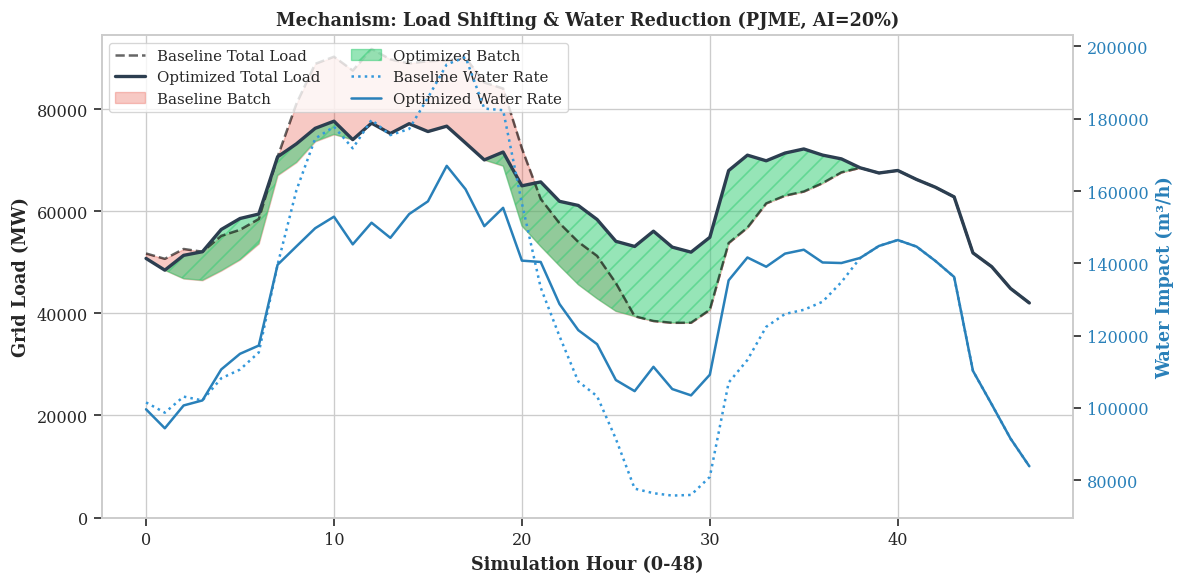

Generating Peaker Dispatch Plot for PJME...


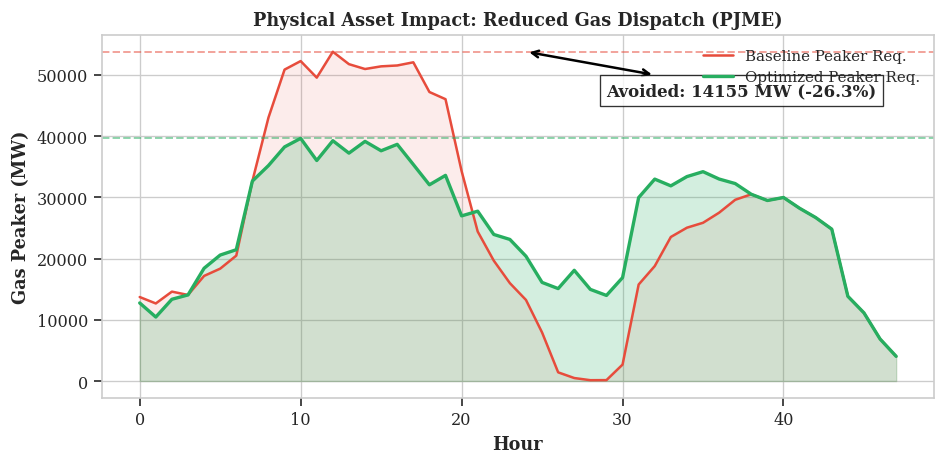

Generating Pareto Curve for PJME...


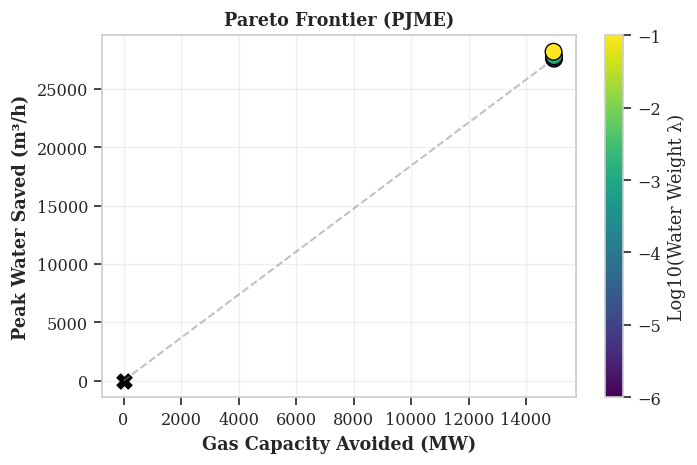

Generating Regional Headline Bar Charts...


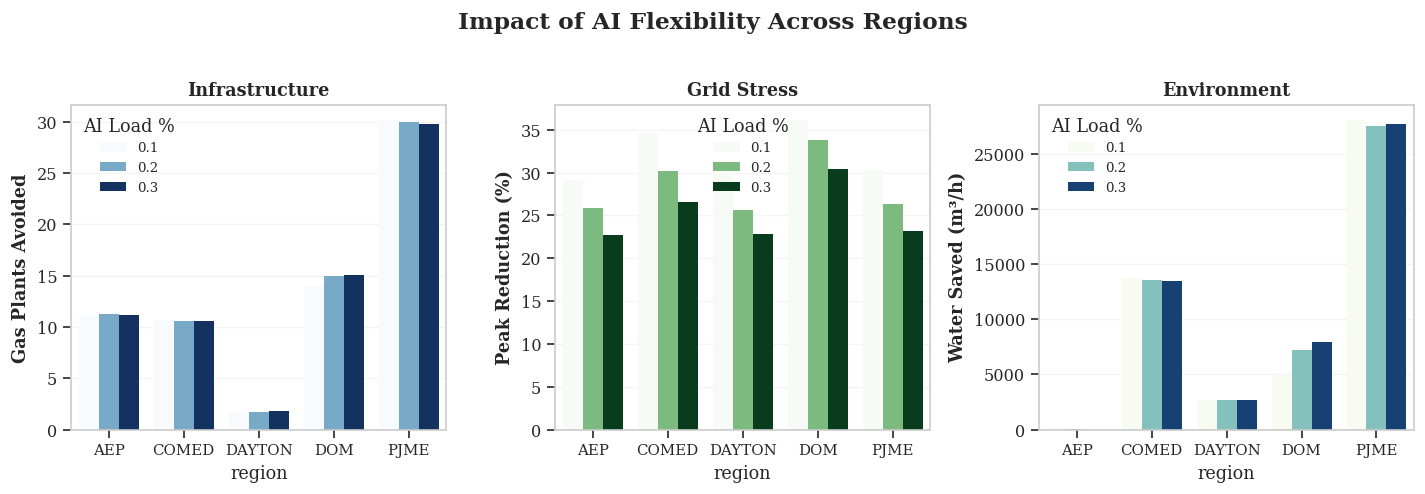

Generating Schematic Impact Map...


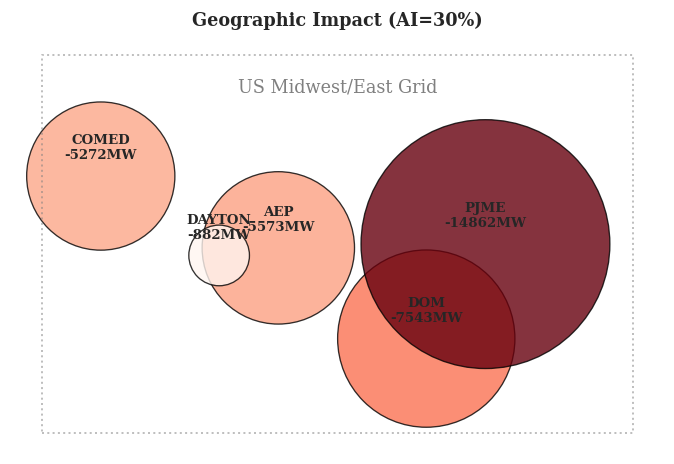

Generating Robustness Boxplots for PJME...


/tmp/ipython-input-3721392128.py:272: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=subset, x='ai_fraction', y='avoided_capacity_mw', ax=ax1, palette='Blues')
/tmp/ipython-input-3721392128.py:276: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=subset, x='ai_fraction', y='water_saved_absolute', ax=ax2, palette='GnBu')


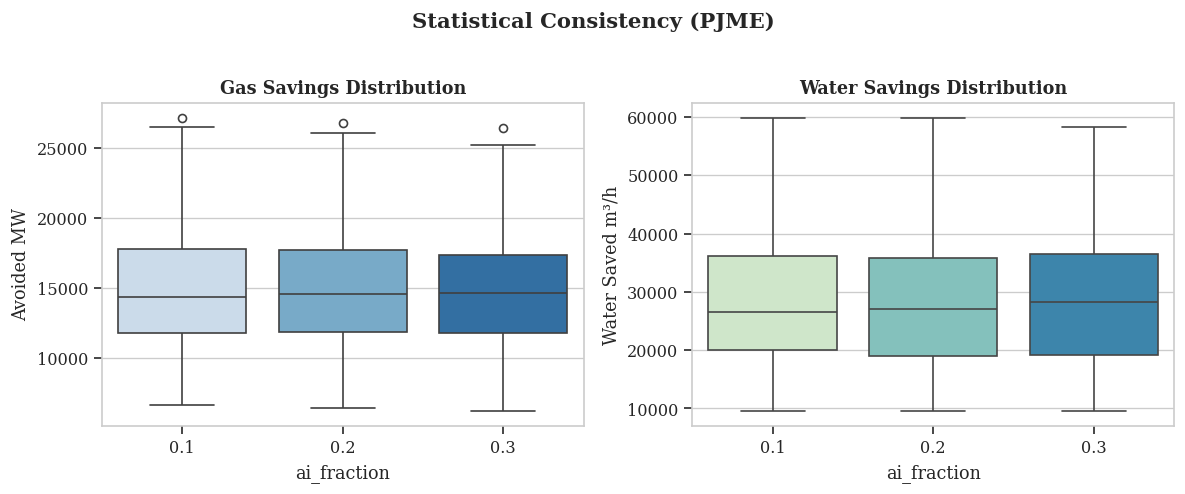

In [ ]:
# @title 6. VISUALIZATION DASHBOARD (Compact Version)
# ==========================================
# 6. VISUALIZATION & ANALYSIS
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Setup Style - Adjusted for compact size
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("paper", font_scale=1.1) # Reduced font scale slightly
plt.rcParams['font.family'] = 'serif'
plt.rcParams['figure.dpi'] = 120

# --- DATA PREP ---
# Load Summary Results
if 'res_df' not in locals():
    res_df = pd.read_csv(os.path.join(BASE_DIR, RESULTS_FILE))

# Load Traces (if not in memory)
if 'trace_df' not in locals():
    trace_path = os.path.join(BASE_DIR, "full_simulation_traces.csv")
    if os.path.exists(trace_path):
        print("Loading full traces from disk...")
        trace_df = pd.read_csv(trace_path)
    else:
        # Fallback if running immediately after Cell 5 without reload
        trace_df = pd.DataFrame(all_traces)

print(f"Data Loaded: {len(res_df)} summary rows, {len(trace_df)} trace rows.")

# Helper to find a representative scenario
def get_scenario(region, ai_frac, trial=0, weight=0.001):
    # Filter for the specific scenario
    subset = trace_df[
        (trace_df['region'] == region) &
        (trace_df['ai_fraction'] == ai_frac) &
        (trace_df['trial'] == trial) &
        (trace_df['water_weight'] == weight)
    ].sort_values('hour')
    return subset

# ==========================================
# 1. MECHANISM FIGURE (Shaded Traces)
# ==========================================
def plot_mechanism(region="PJME", ai_frac=0.20):
    print(f"Generating Mechanism Plot for {region}...")
    # Get trial 0 as representative
    df = get_scenario(region, ai_frac)
    if df.empty:
        print("Scenario not found. Skipping.")
        return

    # REDUCED SIZE: (12, 7) -> (10, 5)
    fig, ax1 = plt.subplots(figsize=(10, 5))

    # X-Axis: Simulation Hour
    x = range(len(df))

    # --- PLOT LOADS (Primary Axis) ---
    # Baseline Total
    ax1.plot(x, df['L_total_base'], color='black', linestyle='--', linewidth=1.5, label='Baseline Total Load', alpha=0.6)

    # Optimized Total
    ax1.plot(x, df['L_total_opt'], color='#2c3e50', linewidth=2, label='Optimized Total Load')

    # Shaded Batch Load (Baseline)
    base_non_batch = df['L_total_base'] - df['L_batch_base']
    ax1.fill_between(x, base_non_batch, df['L_total_base'], color='#e74c3c', alpha=0.3, label='Baseline Batch')

    # Shaded Batch Load (Optimized)
    opt_non_batch = df['L_total_opt'] - df['L_batch_opt']
    ax1.fill_between(x, opt_non_batch, df['L_total_opt'], color='#2ecc71', alpha=0.5, hatch='//', label='Optimized Batch')

    ax1.set_ylabel("Grid Load (MW)", fontweight='bold')
    ax1.set_xlabel("Simulation Hour (0-48)", fontweight='bold')
    ax1.set_ylim(bottom=0)

    # --- WATER RATE (Secondary Axis) ---
    ax2 = ax1.twinx()
    ax2.plot(x, df['w_rate_base'], color='#3498db', linestyle=':', linewidth=1.5, label='Baseline Water Rate')
    ax2.plot(x, df['w_rate_opt'], color='#2980b9', linewidth=1.5, label='Optimized Water Rate')
    ax2.set_ylabel("Water Impact (m³/h)", color='#2980b9', fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='#2980b9')
    ax2.grid(False)

    # Combined Legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True, fontsize=9, ncol=2)

    plt.title(f"Mechanism: Load Shifting & Water Reduction ({region}, AI={int(ai_frac*100)}%)", fontweight='bold')
    plt.tight_layout()
    plt.show()

# ==========================================
# 2. GAS PEAKER DISPATCH
# ==========================================
def plot_peaker_dispatch(region="PJME", ai_frac=0.20):
    print(f"Generating Peaker Dispatch Plot for {region}...")
    df = get_scenario(region, ai_frac)
    if df.empty: return

    # REDUCED SIZE: (10, 6) -> (8, 4)
    fig, ax = plt.subplots(figsize=(8, 4))
    x = range(len(df))

    # Plot Traces
    ax.plot(x, df['g_gas_base'], color='#e74c3c', label='Baseline Peaker Req.', linewidth=1.5)
    ax.fill_between(x, 0, df['g_gas_base'], color='#e74c3c', alpha=0.1)

    ax.plot(x, df['g_gas_opt'], color='#27ae60', label='Optimized Peaker Req.', linewidth=2)
    ax.fill_between(x, 0, df['g_gas_opt'], color='#27ae60', alpha=0.2)

    # Peak Lines
    peak_base = df['g_gas_base'].max()
    peak_opt = df['g_gas_opt'].max()
    ax.axhline(peak_base, color='#e74c3c', linestyle='--', alpha=0.5)
    ax.axhline(peak_opt, color='#27ae60', linestyle='--', alpha=0.5)

    # Annotation
    saved_mw = peak_base - peak_opt
    pct_saved = (saved_mw / peak_base) * 100 if peak_base > 0 else 0

    # Arrow
    ax.annotate(f"Avoided: {int(saved_mw)} MW (-{pct_saved:.1f}%)",
                xy=(len(df)//2, peak_base), xytext=(len(df)//2 + 5, (peak_base+peak_opt)/2),
                arrowprops=dict(arrowstyle='<->', linewidth=1.5),
                fontsize=10, fontweight='bold', bbox=dict(fc='white', alpha=0.8))

    ax.set_ylabel("Gas Peaker (MW)", fontweight='bold')
    ax.set_xlabel("Hour", fontweight='bold')
    ax.legend(loc='upper right', fontsize=9)
    plt.title(f"Physical Asset Impact: Reduced Gas Dispatch ({region})", fontweight='bold')
    plt.tight_layout()
    plt.show()

# ==========================================
# 3. PARETO FRONTIER
# ==========================================
def plot_pareto(region="PJME"):
    print(f"Generating Pareto Curve for {region}...")
    subset = res_df[res_df['region'] == region].groupby(['water_weight']).agg({
        'avoided_capacity_mw': 'mean',
        'water_saved_absolute': 'mean'
    }).reset_index().sort_values('water_weight')

    if subset.empty: return

    # REDUCED SIZE: (8, 6) -> (6, 4)
    fig, ax = plt.subplots(figsize=(6, 4))

    # Base Point
    ax.scatter([0], [0], color='black', s=80, label='Baseline', marker='X')

    # Pareto Points
    sc = ax.scatter(subset['avoided_capacity_mw'], subset['water_saved_absolute'],
                    c=np.log10(subset['water_weight'] + 1e-6), cmap='viridis', s=100,
                    edgecolor='k', zorder=10)

    # Connect line
    ax.plot([0] + subset['avoided_capacity_mw'].tolist(),
            [0] + subset['water_saved_absolute'].tolist(),
            color='gray', linestyle='--', alpha=0.5, zorder=1)

    cbar = plt.colorbar(sc)
    cbar.set_label("Log10(Water Weight λ)")

    ax.set_xlabel("Gas Capacity Avoided (MW)", fontweight='bold')
    ax.set_ylabel("Peak Water Saved (m³/h)", fontweight='bold')
    plt.title(f"Pareto Frontier ({region})", fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# ==========================================
# 4. REGIONAL HEADLINE RESULTS
# ==========================================
def plot_regional_headlines():
    print("Generating Regional Headline Bar Charts...")
    rep_weight = 0.001
    df_agg = res_df[res_df['water_weight'] == rep_weight].groupby(['region', 'ai_fraction']).agg({
        'plants_avoided': 'mean',
        'peak_reduction_pct': 'mean',
        'water_saved_absolute': 'mean'
    }).reset_index()

    # REDUCED SIZE: (18, 6) -> (12, 4)
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    # A. Plants Avoided
    sns.barplot(data=df_agg, x='region', y='plants_avoided', hue='ai_fraction', ax=axes[0], palette='Blues')
    axes[0].set_ylabel("Gas Plants Avoided", fontweight='bold')
    axes[0].set_title("Infrastructure", fontweight='bold')

    # B. Peak Reduction %
    sns.barplot(data=df_agg, x='region', y='peak_reduction_pct', hue='ai_fraction', ax=axes[1], palette='Greens')
    axes[1].set_ylabel("Peak Reduction (%)", fontweight='bold')
    axes[1].set_title("Grid Stress", fontweight='bold')

    # C. Water Saved
    sns.barplot(data=df_agg, x='region', y='water_saved_absolute', hue='ai_fraction', ax=axes[2], palette='GnBu')
    axes[2].set_ylabel("Water Saved (m³/h)", fontweight='bold')
    axes[2].set_title("Environment", fontweight='bold')

    for ax in axes:
        ax.legend(title="AI Load %", fontsize=8)
        ax.grid(axis='y', alpha=0.2)
        ax.tick_params(axis='x', labelsize=9)

    plt.suptitle("Impact of AI Flexibility Across Regions", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# ==========================================
# 5. GEOGRAPHIC MAP (Schematic)
# ==========================================
def plot_map_schematic():
    print("Generating Schematic Impact Map...")
    coords = {
        "COMED": (-88, 41.8), "AEP": (-82, 39.9), "DAYTON":(-84, 39.7),
        "PJME":  (-75, 40.0), "DOM": (-77, 37.5)
    }

    target_ai = 0.30
    df_map = res_df[
        (res_df['ai_fraction'] == target_ai) &
        (res_df['water_weight'] == 0.001)
    ].groupby('region')['avoided_capacity_mw'].mean().reset_index()

    # REDUCED SIZE: (10, 6) -> (7, 4.5)
    fig, ax = plt.subplots(figsize=(7, 4.5))

    # Background
    ax.plot([-90, -70, -70, -90, -90], [35, 35, 45, 45, 35], color='gray', linestyle=':', alpha=0.5)
    ax.text(-80, 44, "US Midwest/East Grid", ha='center', color='gray')

    # Nodes
    x_vals, y_vals, sizes, labels = [], [], [], []
    for _, row in df_map.iterrows():
        reg = row['region']
        if reg in coords:
            x_vals.append(coords[reg][0])
            y_vals.append(coords[reg][1])
            sizes.append(row['avoided_capacity_mw'] * 1.5)
            labels.append(f"{reg}\n-{int(row['avoided_capacity_mw'])}MW")

    sc = ax.scatter(x_vals, y_vals, s=sizes, c=sizes, cmap='Reds', alpha=0.8, edgecolor='k')

    for i, txt in enumerate(labels):
        ax.annotate(txt, (x_vals[i], y_vals[i]), xytext=(0, 10), textcoords='offset points', ha='center', fontweight='bold', fontsize=8)

    plt.title(f"Geographic Impact (AI={int(target_ai*100)}%)", fontweight='bold')
    plt.axis('off')
    plt.show()

# ==========================================
# 6. ROBUSTNESS (Boxplots)
# ==========================================
def plot_robustness(region="PJME"):
    print(f"Generating Robustness Boxplots for {region}...")
    subset = res_df[(res_df['region'] == region) & (res_df['water_weight'] == 0.001)]

    # REDUCED SIZE: (14, 6) -> (10, 4)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

    sns.boxplot(data=subset, x='ai_fraction', y='avoided_capacity_mw', ax=ax1, palette='Blues')
    ax1.set_title("Gas Savings Distribution", fontweight='bold')
    ax1.set_ylabel("Avoided MW")

    sns.boxplot(data=subset, x='ai_fraction', y='water_saved_absolute', ax=ax2, palette='GnBu')
    ax2.set_title("Water Savings Distribution", fontweight='bold')
    ax2.set_ylabel("Water Saved m³/h")

    plt.suptitle(f"Statistical Consistency ({region})", fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# ==========================================
# EXECUTE VISUALIZATIONS
# ==========================================
if not res_df.empty:
    plot_mechanism("PJME", 0.20)
    plot_peaker_dispatch("PJME", 0.20)
    plot_pareto("PJME")
    plot_regional_headlines()
    plot_map_schematic()
    plot_robustness("PJME")
else:
    print("No results found. Please run Cell 5 first.")



---



In [5]:
# @title If colab session disconnects, start here to generate graphs.
import pandas as pd
import os
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define your file paths (Update these to match your actual Drive paths)
# For example: '/content/drive/My Drive/Your_Folder/traces.csv'

results_file = "final_scientific_results_optimized.csv"
results_csv_path = os.path.join(BASE_DIR, results_file)
results_df = pd.read_csv(results_csv_path)

trace_file = "full_simulation_traces.csv"
traces_csv_path = os.path.join(BASE_DIR, trace_file)
trace_df = pd.read_csv(traces_csv_path)

# 3. Define the directory where you want to save the plots
if not os.path.exists(BASE_DIR):
    os.makedirs(BASE_DIR)

print(f"Data loaded successfully. Found {len(results_df)} rows and regions: {results_df['region'].unique()}")
print(f"Data loaded successfully. Found {len(trace_df)} rows and regions: {trace_df['region'].unique()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data loaded successfully. Found 15750 rows and regions: ['PJME' 'COMED' 'AEP' 'DAYTON' 'DOM']
Data loaded successfully. Found 756000 rows and regions: ['PJME' 'COMED' 'AEP' 'DAYTON' 'DOM']




---



Generating Compact Pareto Frontier for PJME...


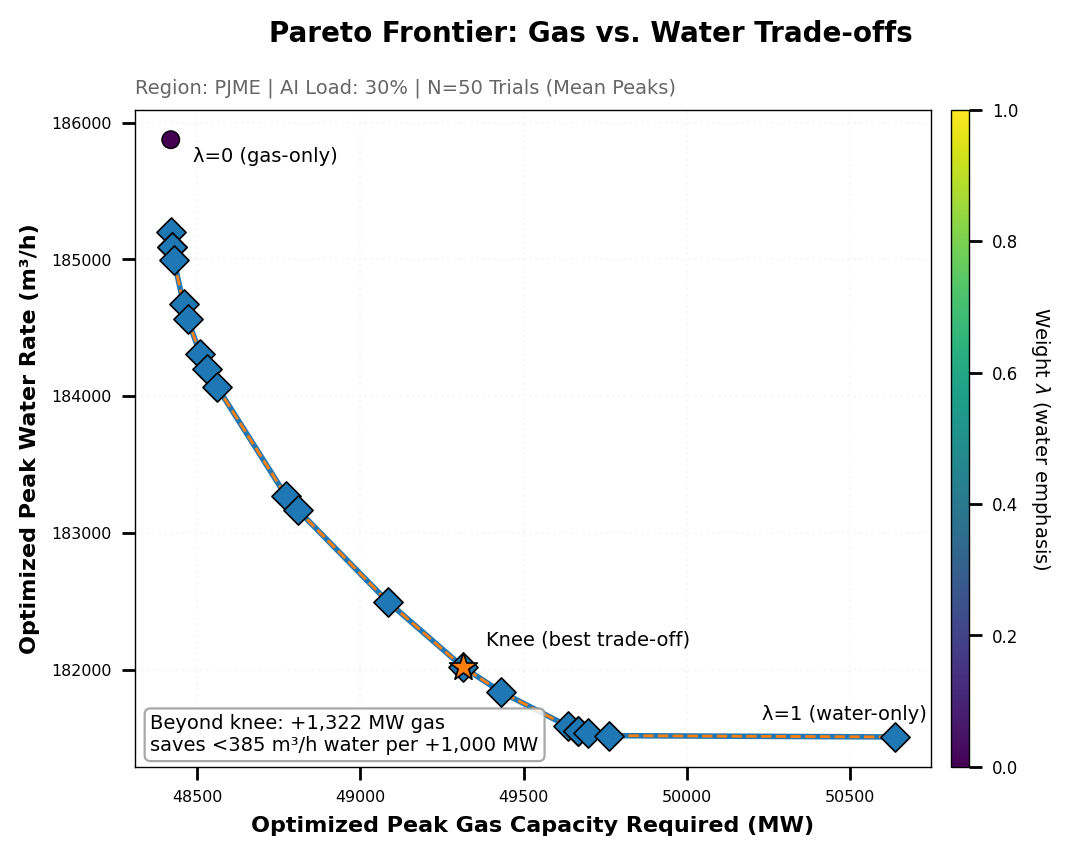

In [86]:
# @title Chart 1: PARETO FRONTIER CHART
def plot_pareto_frontier_compact(region="PJME", ai_frac=0.30, drought_scen=1.0):
    print(f"Generating Compact Pareto Frontier for {region}...")

    # --- 1) Filter from results_df (cleaner than rebuilding from trace_df) ---
    df_src = results_df.copy()
    mask = (df_src["region"] == region) & (df_src["ai_fraction"] == ai_frac)
    if "drought_scenario" in df_src.columns:
        mask &= (df_src["drought_scenario"] == drought_scen)

    sub = df_src.loc[mask].copy()
    if sub.empty:
        print("❌ No data found.")
        return

    # --- 2) Aggregate one Pareto point per lambda (mean across trials) ---
    df_p = (
        sub.groupby("water_weight", as_index=False)
          .agg(
              C_base=("baseline_capacity_mw", "mean"),
              avoided=("avoided_capacity_mw", "mean"),
              W_peak_opt=("water_peak_m3h", "mean")
          )
          .rename(columns={"water_weight": "lambda"})
    )

    # Compute optimized gas peak from saved metric
    df_p["C_peak_opt"] = df_p["C_base"] - df_p["avoided"]
    df_p["W_peak_opt"] = df_p["W_peak_opt"]

    # Color by lambda directly (since you now use 0..1 weights)
    df_p["lambda_clipped"] = df_p["lambda"].clip(0.0, 1.0)



    # --- 3) Build the Pareto frontier (minimize C_peak_opt and W_peak_opt) ---
    df_p = df_p.sort_values(["C_peak_opt", "W_peak_opt"]).reset_index(drop=True)

    X = df_p[["C_peak_opt", "W_peak_opt"]].to_numpy()
    keep = np.ones(len(X), dtype=bool)
    eps = 1e-9

    for i in range(len(X)):
        if not keep[i]:
            continue
        # i is dominated if there exists j with:
        # C_j <= C_i AND W_j <= W_i, with at least one strict
        dominated = (
            (X[:, 0] <= X[i, 0] + eps) &
            (X[:, 1] <= X[i, 1] + eps) &
            ((X[:, 0] < X[i, 0] - eps) | (X[:, 1] < X[i, 1] - eps))
        )
        if np.any(dominated):
            keep[i] = False

    front = df_p.loc[keep].copy()
    front = front.sort_values("C_peak_opt").reset_index(drop=True)


    # --- Knee point (elbow): max distance from chord connecting endpoints ---
    fx = front["C_peak_opt"].to_numpy()
    fy = front["W_peak_opt"].to_numpy()
    i = np.argsort(fx); fx, fy = fx[i], fy[i]

    x0, y0 = fx[0], fy[0]
    x1, y1 = fx[-1], fy[-1]

    # Perpendicular distance from each point to the line through endpoints
    den = np.hypot(x1 - x0, y1 - y0) + 1e-12
    dist = np.abs((y1 - y0)*fx - (x1 - x0)*fy + x1*y0 - y1*x0) / den

    #k = int(np.argmax(dist))
    k = int(np.argmax(dist[1:-1]) + 1)

    knee_x, knee_y = fx[k], fy[k]


    # --- 4) Smooth curve: piecewise-linear interpolation ---
    x = front["C_peak_opt"].to_numpy()
    y = front["W_peak_opt"].to_numpy()

    idx_sort = np.argsort(x)
    x = x[idx_sort]
    y = y[idx_sort]

    # Remove near-duplicate x values by keeping the best (lowest) y at each x bin
    x_round = np.round(x, 6)
    x_u = []
    y_u = []
    i = 0
    while i < len(x):
        j = i
        best_y = y[i]
        while j < len(x) and x_round[j] == x_round[i]:
            best_y = min(best_y, y[j])
            j += 1
        x_u.append(x[i])
        y_u.append(best_y)
        i = j

    x = np.array(x_u)
    y = np.array(y_u)

    # Enforce Pareto-like shape: as C increases, W should not increase (non-increasing)
    y = np.minimum.accumulate(y)

    if len(x) >= 2:
        x_dense = np.linspace(x.min(), x.max(), 250)
        y_dense = np.interp(x_dense, x, y)
    else:
        x_dense, y_dense = x, y


    # --- 5) Plot ---
    fig, ax = plt.subplots(figsize=(6, 4.5))

    # Smooth frontier line
    ax.plot(x_dense, y_dense, linewidth=2.0, zorder=2)

    # Optional: also draw the actual frontier points connected (so judges see it’s data-driven)
    ax.plot(x, y, linestyle="--", linewidth=1.0, zorder=2)

    # Scatter all lambda points
    sc = ax.scatter(
        # COMMENT OUT:
        # df_p["gas_saved"], df_p["water_saved"],
        # ADD:
        df_p["C_peak_opt"], df_p["W_peak_opt"],
        c=df_p["lambda_clipped"], cmap="viridis",
        s=40, zorder=3, edgecolors="k", linewidth=0.5
    )

    # Highlight frontier points
    ax.scatter(
        # COMMENT OUT:
        # front["gas_saved"], front["water_saved"],
        # ADD:
        front["C_peak_opt"], front["W_peak_opt"],
        s=55, marker="D", zorder=4, edgecolors="k", linewidth=0.6
    )


    ax.scatter([knee_x], [knee_y], s=110, marker="*", zorder=5, edgecolors="k", linewidth=0.6)
    ax.annotate("Knee (best trade-off)", (knee_x, knee_y),
                textcoords="offset points", xytext=(8, 8), fontsize=7)



    # --- Textbox: diminishing returns beyond the knee ---
    # Use last point as the "water-only" end
    x_end, y_end = fx[-1], fy[-1]

    dC_post = x_end - knee_x                     # extra MW gas required beyond knee
    dW_post = max(0.0, knee_y - y_end)           # additional water reduction beyond knee (m3/h)

    # Avoid divide-by-zero; compute "per +1000 MW" headline
    mw_per = 1000.0
    if dC_post > 1e-9:
        water_per_1000mw = dW_post * (mw_per / dC_post)
    else:
        water_per_1000mw = 0.0

    msg = (f"Beyond knee: +{dC_post:,.0f} MW gas\n"
          f"saves <{water_per_1000mw:,.0f} m³/h water per +1,000 MW")

    ax.text(0.02, 0.08, msg, transform=ax.transAxes, fontsize=7,
            va="top", ha="left",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.85, edgecolor="0.6"))



    # ADD:
    ax.set_xlabel("Optimized Peak Gas Capacity Required (MW)", fontweight="bold", fontsize=8)
    ax.set_ylabel("Optimized Peak Water Rate (m³/h)", fontweight="bold", fontsize=8)

    # Colorbar
    cbar = plt.colorbar(sc, ax=ax, pad=0.02, aspect=35)
    cbar.set_label(r"Weight $\lambda$ (water emphasis)", fontsize=7, rotation=270, labelpad=12)
    cbar.ax.tick_params(labelsize=6)

    plt.suptitle("Pareto Frontier: Gas vs. Water Trade-offs", fontsize=10, fontweight="bold", y=0.98)
    ax.set_title(f"Region: {region} | AI Load: {ai_frac:.0%} | N=50 Trials (Mean Peaks)", fontsize=7, color="#666", loc="left")
    ax.grid(True, linestyle=":", alpha=0.5)

    # Optional: label extreme weights
    min_row = df_p.loc[df_p["lambda"].idxmin()]
    max_row = df_p.loc[df_p["lambda"].idxmax()]


    ax.annotate("λ=0 (gas-only)",
                (min_row["C_peak_opt"], min_row["W_peak_opt"]),
                textcoords="offset points", xytext=(8, -8), fontsize=7, ha="left")

    ax.annotate("λ=1 (water-only)",
                (max_row["C_peak_opt"], max_row["W_peak_opt"]),
                textcoords="offset points", xytext=(-48, 6), fontsize=7, ha="left")



    plt.subplots_adjust(top=0.88, bottom=0.15, left=0.12, right=0.92)
    #ax.invert_xaxis()
    #ax.invert_yaxis()
    plt.show()


if 'trace_df' in locals():
    plot_pareto_frontier_compact(region="PJME", ai_frac=0.30, drought_scen=1.0)

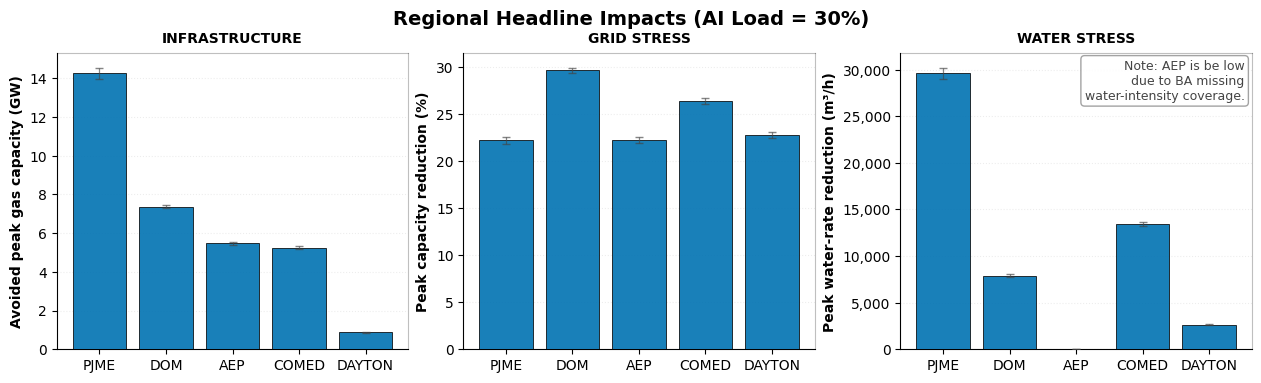

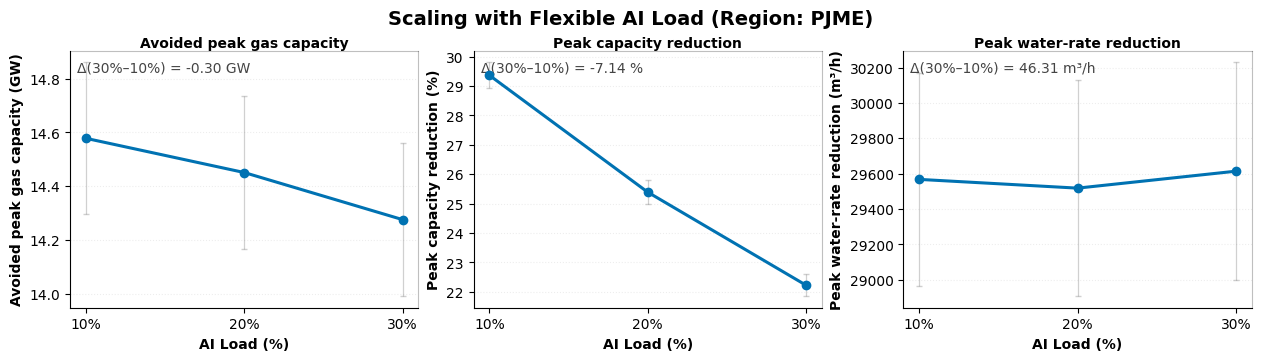

In [84]:
# @title Chart 2: FINAL REGIONAL HEADLINE IMPACT SUMMARY
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- helpers ----------
def _mean_ci95(x):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)
    if n == 0:
        return np.nan, np.nan, 0
    m = float(np.mean(x))
    if n == 1:
        return m, 0.0, 1
    se = float(np.std(x, ddof=1) / np.sqrt(n))
    return m, 1.96 * se, n  # ~95% CI

def _agg_mean_ci(df, group_cols, value_col):
    rows = []
    for keys, g in df.groupby(group_cols, dropna=False):
        m, ci, n = _mean_ci95(g[value_col].to_numpy())
        if not isinstance(keys, tuple):
            keys = (keys,)
        rows.append((*keys, m, ci, n))
    out = pd.DataFrame(rows, columns=[*group_cols, "mean", "ci95", "n"])
    return out

# Colorblind-safe (Okabe–Ito)
COLORS = {
    "blue":  "#0072B2",
    "orange":"#E69F00",
    "green": "#009E73",
    "gray":  "#444444",
    "light": "#EEEEEE"
}


if "avoided_capacity_mw" in results_df.columns and "avoided_capacity_gw" not in results_df.columns:
    results_df["avoided_capacity_gw"] = results_df["avoided_capacity_mw"] / 1000.0


# ---------- FIGURE A: Regional headline (AI=30%) ----------
def plot_regional_headline_ai30(df,
                               ai_level=0.30,
                               region_col="region",
                               ai_col="ai_fraction",
                               #metrics=("plants_avoided", "peak_reduction_pct", "water_saved_absolute"),
                               metrics=("avoided_capacity_gw", "peak_reduction_pct", "water_saved_absolute"),
                               metric_titles=("INFRASTRUCTURE", "GRID STRESS", "WATER STRESS"),
                               #ylabels=("Peakers avoided (500 MW/plant)",
                               ylabels=("Avoided peak gas capacity (GW)",
                                        "Peak capacity reduction (%)",
                                        "Peak water-rate reduction (m³/h)"),
                               figsize=(12.5, 3.5)):

    d = df.copy()
    needed = [region_col, ai_col, *metrics]
    miss = [c for c in needed if c not in d.columns]
    if miss:
        raise ValueError(f"Missing columns: {miss}")

    d = d.loc[d[ai_col] == ai_level].copy()
    if d.empty:
        raise ValueError(f"No rows found for ai_fraction == {ai_level}")

    # Sort regions by infrastructure impact for instant story
    infra = _agg_mean_ci(d, [region_col], metrics[0]).sort_values("mean", ascending=False)
    order = infra[region_col].tolist()

    fig, axes = plt.subplots(1, 3, figsize=figsize, constrained_layout=True)

    fig.suptitle(f"Regional Headline Impacts (AI Load = {int(ai_level*100)}%)",
                 fontsize=14, fontweight="bold", y=1.05)

    for ax, metric, title, yl in zip(axes, metrics, metric_titles, ylabels):
        s = _agg_mean_ci(d, [region_col], metric)
        s[region_col] = pd.Categorical(s[region_col], categories=order, ordered=True)
        s = s.sort_values(region_col)

        x = np.arange(len(order))
        ax.bar(
            x, s["mean"].to_numpy(),
            yerr=s["ci95"].to_numpy(),
            capsize=3,
            color=COLORS["blue"],
            alpha=0.90,
            edgecolor="black",
            linewidth=0.6,
            error_kw=dict(ecolor=COLORS["gray"], lw=0.9, alpha=0.65),
            zorder=3
        )

        # Benchmark line: median region (AI=30%)
        # med = float(np.nanmedian(s["mean"].to_numpy()))
        # ax.axhline(med, linestyle="--", linewidth=1.0, color=COLORS["gray"], alpha=0.45, zorder=2)
        # ax.text(0.99, 0.02, "median (AI=30%)", transform=ax.transAxes,
        #         ha="right", va="bottom", fontsize=9, color=COLORS["gray"])

        # ax.text(0.98, 0.44, "Median", transform=ax.transAxes,
        #         ha="right", va="bottom", fontsize=9, color=COLORS["gray"],
        #         bbox=dict(boxstyle="round,pad=0.15", facecolor="white", alpha=0.8, edgecolor="none"))


        # Highlight top region with ★
        # top_idx = int(np.nanargmax(s["mean"].to_numpy()))
        # ax.text(top_idx, s["mean"].iloc[top_idx] + (s["ci95"].iloc[top_idx] or 0)*1.2,
        #         "★", ha="center", va="bottom", fontsize=16, color=COLORS["orange"])
        # ax.text(top_idx, s["mean"].iloc[top_idx],
        #         "★", ha="center", va="bottom", fontsize=12, color=COLORS["orange"])



        ax.set_title(title, fontweight="bold", pad=8, fontsize=10)
        ax.set_ylabel(yl, fontweight="bold")



        if metric == metrics[2]:  # ENV panel
           ax.ticklabel_format(axis="y", style="plain", useOffset=False)

        ax.get_yaxis().set_major_formatter(
            plt.FuncFormatter(lambda v, _: f"{int(v):,}" if abs(v) >= 1000 else f"{v:g}")
        )



        ax.set_xticks(x)
        ax.set_xticklabels(order)
        ax.grid(axis="y", linestyle=":", alpha=0.22)
        ax.set_axisbelow(True)
        for sp in ("top", "right"):
            ax.spines[sp].set_alpha(0.25)


        # Add AEP note in a top-right textbox (only on WATER STRESS panel)
        if title == "WATER STRESS":  # or: if metric == "water_saved_absolute":
            ax.text(0.98, 0.98,
                    "Note: AEP is be low\n due to BA missing\nwater-intensity coverage.",
                    transform=ax.transAxes,
                    ha="right", va="top",
                    fontsize=9, color="#444",
                    bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                              alpha=0.9, edgecolor="0.6"))

    plt.show()


# ---------- FIGURE B: Scaling curve (PJME only) ----------
def plot_scaling_curve_pjme(df,
                            region="PJME",
                            region_col="region",
                            ai_col="ai_fraction",
                            ai_levels=(0.10, 0.20, 0.30),
                            # metrics=("plants_avoided", "peak_reduction_pct", "water_saved_absolute"),
                            # metric_titles=("Peakers avoided", "Peak reduction", "Peak water saved"),
                            # ylabels=("Peakers avoided (500 MW/plant)",
                            #          "Peak capacity reduction (%)",
                            #          "Peak water-impact saved (m³/h)"),

                            metrics=("avoided_capacity_gw", "peak_reduction_pct", "water_saved_absolute"),
                            metric_titles=("Avoided peak gas capacity", "Peak capacity reduction", "Peak water-rate reduction"),
                            ylabels=("Avoided peak gas capacity (GW)",
                                    "Peak capacity reduction (%)",
                                    "Peak water-rate reduction (m³/h)"),

                            figsize=(12.5, 3.5)):

    d = df.copy()
    needed = [region_col, ai_col, *metrics]
    miss = [c for c in needed if c not in d.columns]
    if miss:
        raise ValueError(f"Missing columns: {miss}")

    d = d.loc[d[region_col] == region].copy()
    if d.empty:
        raise ValueError(f"No rows found for region == {region}")

    ai_levels = list(ai_levels)
    xs = np.array([int(round(a*100)) for a in ai_levels], dtype=float)

    fig, axes = plt.subplots(1, 3, figsize=figsize, constrained_layout=True)
    # fig, axes = plt.subplots(1, 3, figsize=figsize)

    fig.suptitle(f"Scaling with Flexible AI Load (Region: {region})",
                 fontsize=14, fontweight="bold")
    # fig.text(0.5, 0.92,
    #      "Mean across 50 trials; error bars = 95% CI. AI Load (%) = AI share of node peak demand.",
    #      ha="center", va="center", fontsize=8, color="#444")
    # fig.text(0.5, 0.94,
    #         "Bars show mean across trials; error bars = 95% CI. ★ marks the highest mean in each panel; dashed line = median.",
    #         ha="center", va="center", fontsize=7, color="#444")
    # fig.subplots_adjust(top=0.82, wspace=0.25)

    for ax, metric, ttl, yl in zip(axes, metrics, metric_titles, ylabels):
        rows = []
        for a in ai_levels:
            vals = d.loc[d[ai_col] == a, metric].to_numpy()
            m, ci, n = _mean_ci95(vals)
            rows.append((a, m, ci, n))
        s = pd.DataFrame(rows, columns=[ai_col, "mean", "ci95", "n"]).sort_values(ai_col)

        y = s["mean"].to_numpy()
        ci = s["ci95"].to_numpy()

        ax.plot(xs, y, marker="o", linewidth=2.2, color=COLORS["blue"], zorder=4)
        #ax.fill_between(xs, y - ci, y + ci, color=COLORS["blue"], alpha=0.15, linewidth=0, zorder=2)
        ax.errorbar(xs, y, yerr=ci, fmt="none", ecolor=COLORS["gray"], elinewidth=0.9, capsize=2, alpha=0.25, zorder=3)

        ax.set_title(ttl, fontweight="bold", pad=2, fontsize=10)
        ax.set_ylabel(yl, fontweight="bold")
        ax.set_xlabel("AI Load (%)", fontweight="bold")
        ax.set_xticks(xs)
        ax.set_xticklabels([f"{int(v)}%" for v in xs])
        ax.grid(axis="y", linestyle=":", alpha=0.22)
        ax.set_axisbelow(True)
        for sp in ("top", "right"):
            ax.spines[sp].set_alpha(0.25)

        # Micro-story note: net change from 10% to 30%
        if np.all(np.isfinite(y)):
            delta = y[-1] - y[0]
            # ax.text(0.02, 0.96, f"Δ(30%-10%) = {delta:,.2f}",
            #         transform=ax.transAxes, ha="left", va="top",
            #         fontsize=10, color=COLORS["gray"])

            # ADD: unit-aware delta annotation
            unit = "GW" if metric == "avoided_capacity_gw" else ("%" if metric == "peak_reduction_pct" else "m³/h")
            ax.text(0.02, 0.96, f"Δ(30%–10%) = {delta:,.2f} {unit}",
                    transform=ax.transAxes, ha="left", va="top",
                    fontsize=10, color=COLORS["gray"])


        # # ADD: interpretive note (judge-friendly), only on the Peak reduction panel
        # if metric == "peak_reduction_pct":
        #     ax.text(0.02, 0.08,
        #             "As AI load rises, the non-shiftable (online) share grows,\n"
        #             "so scheduling flexibility is a smaller fraction of total peak.",
        #             transform=ax.transAxes, ha="left", va="bottom",
        #             fontsize=9, color="#666",
        #             bbox=dict(boxstyle="round,pad=0.25", facecolor="white", alpha=0.85, edgecolor="0.7"))

        # ADD: commas on large water values
        if metric == "water_saved_absolute":
            ax.ticklabel_format(axis="y", style="plain", useOffset=False)

    plt.show()


# ---- Example usage ----
plot_regional_headline_ai30(results_df, ai_level=0.30)
plot_scaling_curve_pjme(results_df, region="PJME")


Generating Ultra-Compact Peaker Plot for PJME...


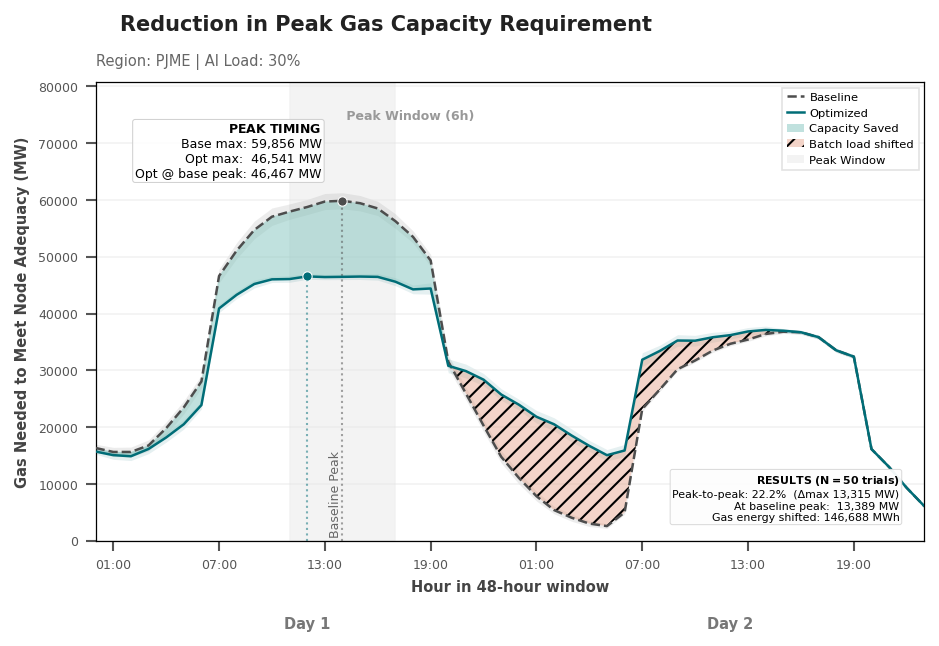

In [108]:
# @title Chart 3: FINAL PEAKER DISPATCH PLOT
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# --- 1. SETUP & STYLE ---
plt.style.use('default')

# Compact "Journal" Aesthetic
sns.set_context("paper", font_scale=0.75)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['grid.color'] = '#e5e5e5'

# Colors
C_BASE = '#4d4d4d'
C_OPT = '#006d77'
C_SAVE = '#83c5be'
C_SHIFT = '#e29578'
C_WINDOW = '#f0f0f0'

def plot_peaker_dispatch_ultra_compact(region="PJME", ai_frac=0.30, water_weight=0.0):
    print(f"Generating Ultra-Compact Peaker Plot for {region}...")

    # --- 2. DATA PREPARATION ---
    subset = trace_df[
        (trace_df['region'] == region) &
        (trace_df['ai_fraction'] == ai_frac) &
        (trace_df['water_weight'] == water_weight)
    ]

    if subset.empty:
        print("❌ No data found. Run Cell 5 first.")
        return

    dates = pd.date_range(start="2025-07-15 00:00", periods=48, freq="h")

    stats = subset.groupby('hour').agg({
        'g_gas_base': ['mean', 'std', 'count'],
        'g_gas_opt': ['mean', 'std']
    })
    stats.columns = ['_'.join(col).strip() for col in stats.columns.values]
    stats['timestamp'] = dates

    N = stats['g_gas_base_count'].iloc[0]
    ci_mult = 1.96 / np.sqrt(N)

    idx_peak_base = stats['g_gas_base_mean'].argmax()
    idx_peak_opt = stats['g_gas_opt_mean'].argmax()

    window_start = max(0, idx_peak_base - 3)
    window_end = min(47, idx_peak_base + 3)

    # --- 3. PLOTTING ---
    fig, ax = plt.subplots(figsize=(6.5, 4.5))

    # A. Critical Window
    ax.axvspan(stats['timestamp'].iloc[window_start],
               stats['timestamp'].iloc[window_end],
               color=C_WINDOW, alpha=0.8, zorder=0)

    # Label: Peak Window
    #win_center_time = stats['timestamp'].iloc[window_start]
    win_center_time = stats['timestamp'].iloc[(window_start + window_end)//2]

    top_lim = stats['g_gas_base_mean'].max() * 1.35
    ax.text(win_center_time, top_lim * 0.94, " Peak Window (6h)",
            color='#999', fontsize=6, va='top', fontweight='bold')

    # B. Uncertainty Bands
    ax.fill_between(stats['timestamp'],
                    stats['g_gas_base_mean'] - stats['g_gas_base_std']*ci_mult,
                    stats['g_gas_base_mean'] + stats['g_gas_base_std']*ci_mult,
                    color=C_BASE, alpha=0.1, zorder=1, linewidth=0)
    ax.fill_between(stats['timestamp'],
                    stats['g_gas_opt_mean'] - stats['g_gas_opt_std']*ci_mult,
                    stats['g_gas_opt_mean'] + stats['g_gas_opt_std']*ci_mult,
                    color=C_OPT, alpha=0.1, zorder=1, linewidth=0)

    # C. Difference Shading
    ax.fill_between(stats['timestamp'], stats['g_gas_opt_mean'], stats['g_gas_base_mean'],
                    where=(stats['g_gas_base_mean'] > stats['g_gas_opt_mean']),
                    facecolor=C_SAVE, alpha=0.5, interpolate=True, zorder=2)
    ax.fill_between(stats['timestamp'], stats['g_gas_opt_mean'], stats['g_gas_base_mean'],
                    where=(stats['g_gas_opt_mean'] >= stats['g_gas_base_mean']),
                    facecolor=C_SHIFT, alpha=0.4, hatch='///', interpolate=True, zorder=2)

    # D. Traces
    ax.plot(stats['timestamp'], stats['g_gas_base_mean'],
            color=C_BASE, linestyle='--', lw=1.2, label='Baseline', zorder=3)
    ax.plot(stats['timestamp'], stats['g_gas_opt_mean'],
            color=C_OPT, linestyle='-', lw=1.2, label='Optimized', zorder=3)

    # --- 4. ANNOTATIONS ---
    val_peak_base = stats['g_gas_base_mean'].iloc[idx_peak_base]
    val_peak_opt = stats['g_gas_opt_mean'].iloc[idx_peak_opt]
    time_peak_base = stats['timestamp'].iloc[idx_peak_base]
    time_peak_opt = stats['timestamp'].iloc[idx_peak_opt]

    # delta_mw = val_peak_base - val_peak_opt
    # delta_pct = (delta_mw / val_peak_base) * 100
    # plants_avoided = delta_mw / 500.0

    # Peak-to-peak (max baseline) - (max optimized)
    delta_mw = val_peak_base - val_peak_opt
    delta_pct = (delta_mw / val_peak_base) * 100

    # At baseline peak hour: baseline peak - optimized at SAME hour
    val_opt_at_base_peak = stats['g_gas_opt_mean'].iloc[idx_peak_base]
    delta_mw_at_base = val_peak_base - val_opt_at_base_peak
    delta_pct_at_base = (delta_mw_at_base / val_peak_base) * 100

    # mwh_base = stats['g_gas_base_mean'].sum()
    # mwh_opt = stats['g_gas_opt_mean'].sum()
    # delta_mwh = mwh_opt - mwh_base
    # dt = 1.0  # hours
    # mwh_base = stats['g_gas_base_mean'].sum() * dt
    # mwh_opt  = stats['g_gas_opt_mean'].sum() * dt
    # delta_mwh = mwh_base - mwh_opt  # positive = saved energy

    dt = 1.0  # hours

    # Total gas energy over 48h (area under curve)
    mwh_base = stats['g_gas_base_mean'].sum() * dt
    mwh_opt  = stats['g_gas_opt_mean'].sum() * dt
    delta_mwh_saved = mwh_base - mwh_opt  # positive = saved energy (often ~0 for pure shifting)

    # Energy shifted (always >= 0 if the profile changes)
    shift_mwh = 0.5 * np.sum(np.abs(stats['g_gas_opt_mean'] - stats['g_gas_base_mean'])) * dt

    # Peak-window gas energy reduction (shows the reliability benefit explicitly)
    mwh_peak_base = stats['g_gas_base_mean'].iloc[window_start:window_end+1].sum() * dt
    mwh_peak_opt  = stats['g_gas_opt_mean'].iloc[window_start:window_end+1].sum() * dt
    delta_peak_mwh = mwh_peak_base - mwh_peak_opt




    # Vertical Drop Lines
    ax.vlines(x=time_peak_base, ymin=0, ymax=val_peak_base, colors=C_BASE, linestyles=':', alpha=0.5, lw=1)
    ax.text(time_peak_base, 0, " Baseline Peak", ha='right', va='bottom',
            fontsize=6, color='#666', rotation=90)

    ax.vlines(x=time_peak_opt, ymin=0, ymax=val_peak_opt, colors=C_OPT, linestyles=':', alpha=0.5, lw=1)

    # Peak Markers
    ax.scatter([time_peak_base], [val_peak_base], color=C_BASE, s=20, zorder=4, edgecolor='white', linewidth=0.5)
    ax.scatter([time_peak_opt], [val_peak_opt], color=C_OPT, s=20, zorder=4, edgecolor='white', linewidth=0.5)

    # BOX A: PEAK TIMING
    # callout_text = (
    #     f"$\\bf{{PEAK\\ TIMING}}$\n"
    #     f"Base: {int(val_peak_base):,} MW\n"
    #     f"Opt:  {int(val_peak_opt):,} MW"
    # )

    callout_text = (
        f"$\\bf{{PEAK\\ TIMING}}$\n"
        f"Base max: {int(val_peak_base):,} MW\n"
        f"Opt max:  {int(val_peak_opt):,} MW\n"
        f"Opt @ base peak: {int(val_opt_at_base_peak):,} MW"
    )



    ax.annotate(callout_text, xy=(time_peak_base, val_peak_base),
                xytext=(-10, 10), textcoords='offset points',
                ha='right', va='bottom', fontsize=6,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.9, ec='#ccc', lw=0.5))

    # BOX B: IMPACT RESULTS (Ultra-Compact)
    # metrics_text = (
    #     f"$\\bf{{RESULTS\\ (N={N} \\ trials)}}$\n"
    #     # f"Peak Gas Reduction: {delta_pct:.1f}%\n"
    #     # f"Capacity Avoided: {int(delta_mw):,} MW\n"
    #     f"Peak-to-peak reduction: {delta_pct:.1f}%\n"
    #     f"  (Δ max): {delta_mw:,.0f} MW\n"
    #     f"At baseline peak hour: {delta_pct_at_base:.1f}%\n"
    #     f"  (Δ @ t*): {delta_mw_at_base:,.0f} MW\n"
    #     # f"$\\approx$ {plants_avoided:.1f} Peaker Plants*\n"
    #     # f"$\\Delta$ Gas Energy: {int(delta_mwh):+,.0f} MWh\n"
    #     # f"(conserved/shifted)"
    #     f"$\\Delta$ Gas Energy (total): {delta_mwh_saved:+,.0f} MWh\n"
    #     f"Gas Energy Shifted: {shift_mwh:,.0f} MWh\n"
    #     f"Peak-Window Gas Energy ↓: {delta_peak_mwh:,.0f} MWh"
    # )

    metrics_text = (
        f"$\\bf{{RESULTS\\ (N={N}\\ trials)}}$\n"
        f"Peak-to-peak: {delta_pct:.1f}%  (Δmax {delta_mw:,.0f} MW)\n"
        f"At baseline peak:  {delta_mw_at_base:,.0f} MW\n"
        f"Gas energy shifted: {shift_mwh:,.0f} MWh"
    )


    # Reduced Fontsize to 5.3 and box padding to 0.2
    ax.text(0.97, 0.04, metrics_text, transform=ax.transAxes,
            fontsize=5.3, linespacing=1.2, va='bottom', ha='right',
            bbox=dict(boxstyle="round,pad=0.2", fc="#fdfdfd", ec="#d9d9d9", alpha=0.95, lw=0.5))

    # ax.text(0.02, 0.02, "*Assumes 500 MW avg. capacity", transform=ax.transAxes,
    #         fontsize=5, color='#777', fontstyle='italic')

    # --- 5. LEGEND & FORMATTING ---
    legend_elements = [
        Line2D([0], [0], color=C_BASE, linestyle='--', lw=1.2, label='Baseline'),
        Line2D([0], [0], color=C_OPT, linestyle='-', lw=1.2, label='Optimized'),
        Patch(facecolor=C_SAVE, alpha=0.5, label='Capacity Saved'),
        Patch(facecolor=C_SHIFT, alpha=0.4, hatch='///', label='Batch load shifted'),
        Patch(facecolor=C_WINDOW, alpha=0.8, label='Peak Window')
    ]

    # Reduced Legend Fontsize to 5.5
    ax.legend(handles=legend_elements, loc='upper right', fontsize=5.5,
              frameon=True, framealpha=0.9, edgecolor='#e0e0e0', fancybox=False,
              handlelength=1.5, handletextpad=0.5)

    ax.set_ylabel("Gas Needed to Meet Node Adequacy (MW)", fontweight='bold', color='#444', fontsize=7)
    ax.set_xlabel("Hour in 48-hour window", fontweight='bold', color='#444', fontsize=7)

    mid_day1 = stats['timestamp'].iloc[12]
    mid_day2 = stats['timestamp'].iloc[36]
    ax.text(mid_day1, -0.19, "Day 1", transform=ax.get_xaxis_transform(),
             ha='center', fontsize=7, fontweight='bold', color='#777')
    ax.text(mid_day2, -0.19, "Day 2", transform=ax.get_xaxis_transform(),
             ha='center', fontsize=7, fontweight='bold', color='#777')

    # --- TITLES ---
    plt.suptitle("Reduction in Peak Gas Capacity Requirement",
                 fontsize=10, fontweight='bold', y=0.96, x=0.125, ha='left', color='#222')

    ax.set_title(f"Region: {region} | AI Load: {ai_frac:.0%}",
                 fontsize=7, color='#666', loc='left', pad=8)

    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:00'))
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=6))
    ax.set_xlim(stats['timestamp'].iloc[0], stats['timestamp'].iloc[-1])
    ax.set_ylim(bottom=0, top=top_lim)

    ax.grid(True, which='major', axis='y', linestyle='-', alpha=0.5, color='#e5e5e5')
    ax.grid(False, axis='x')
    ax.tick_params(colors='#555', labelsize=6)

    plt.subplots_adjust(top=0.86, bottom=0.18, left=0.10, right=0.95)

    #filename = f"{BASE_DIR}/Fig_Peaker_Journal_UltraCompact_{region}.png"
    #plt.savefig(filename, dpi=300, bbox_inches='tight')
    #print(f"✅ Ultra Compact Figure saved to: {filename}")
    plt.show()

# Run
if 'trace_df' in locals():
    plot_peaker_dispatch_ultra_compact(region="PJME", ai_frac=0.30)
else:
    print("Run Cell 5 first.")

/tmp/ipython-input-1135119999.py:74: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipython-input-1135119999.py:74: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipython-input-1135119999.py:74: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


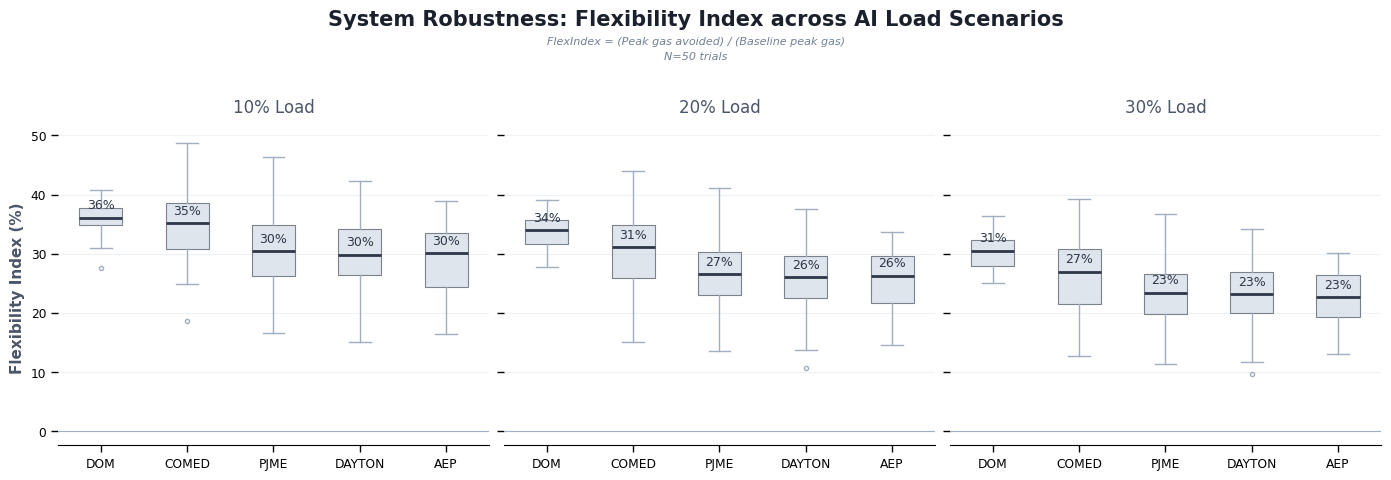

In [20]:
# @title Chart 4: Flexibility Index Distribution (Boxplots)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def add_flexindex(results_df, out_col="FlexIndex"):
    """
    Adds FlexIndex = avoided_capacity_mw / baseline_capacity_mw (unitless fraction).
    """
    df = results_df.copy()
    req = ["avoided_capacity_mw", "baseline_capacity_mw"]
    missing = [c for c in req if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns needed for FlexIndex: {missing}")

    base = df["baseline_capacity_mw"].astype(float).to_numpy()
    avoided = df["avoided_capacity_mw"].astype(float).to_numpy()

    df[out_col] = np.where(np.isfinite(base) & (base > 0), avoided / base, np.nan)
    return df

def plot_flexindex_boxplots(results_df,
                            regions=None,
                            ai_levels=(0.10, 0.20, 0.30),
                            region_col="region",
                            ai_col="ai_fraction",
                            water_weight=0.0,
                            water_weight_col="water_weight",
                            show_percent=True,
                            sort_by_hardest=True,
                            figsize=(14, 5)):

    # --- Build FlexIndex ---
    df = add_flexindex(results_df, out_col="FlexIndex")
    if (water_weight is not None) and (water_weight_col in df.columns):
        df = df.loc[df[water_weight_col] == water_weight].copy()

    ai_levels = list(ai_levels)
    df = df.loc[df[ai_col].isin(ai_levels)].copy()

    y_col = "FlexIndex"
    if show_percent:
        df["FlexIndex_pct"] = 100.0 * df["FlexIndex"]
        y_col = "FlexIndex_pct"

    if sort_by_hardest:
        hardest = max(ai_levels)
        ref = df.loc[df[ai_col] == hardest].copy()
        order = ref.groupby(region_col)[y_col].median().sort_values(ascending=False)
        regions = order.index.tolist()

    # --- Professional Palette (Muted/Academic) ---
    box_color = '#cbd5e0'    # Muted slate gray
    median_color = '#2d3748' # Deep ink blue/black
    whisker_color = '#a0aec0' # Light gray

    fig, axes = plt.subplots(1, len(ai_levels), figsize=figsize, sharey=True, dpi=100)
    if len(ai_levels) == 1: axes = [axes]

    # Clean Typography
    fig.suptitle("System Robustness: Flexibility Index across AI Load Scenarios",
                 fontsize=15, fontweight="600", color='#1a202c', y=0.98)

    note = "FlexIndex = (Peak gas avoided) / (Baseline peak gas)"
    fig.text(0.5, 0.91, note, ha="center", fontsize=8, color="#718096", style='italic')

    note_2 = "N=50 trials"
    fig.text(0.5, 0.88, note_2, ha="center", fontsize=8, color="#718096", style='italic')


    for ax, a in zip(axes, ai_levels):
        sub = df.loc[df[ai_col] == a].copy()
        data = [sub.loc[sub[region_col] == r, y_col].dropna().to_numpy() for r in regions]

        bp = ax.boxplot(
            data,
            labels=regions,
            patch_artist=True,
            showfliers=True,
            widths=0.5, # Reduced width for less "bulky" look
            flierprops={'marker': 'o', 'markersize': 3, 'markeredgecolor': whisker_color}
        )

        for box in bp["boxes"]:
            box.set(facecolor=box_color, alpha=0.6, edgecolor=median_color, linewidth=0.8)
        for median in bp["medians"]:
            median.set(color=median_color, linewidth=2)
        for whisk in bp["whiskers"]:
            whisk.set(color=whisker_color, linewidth=1, linestyle='-')
        for cap in bp["caps"]:
            cap.set(color=whisker_color)

        # Subtle median labels
        for i, v in enumerate(data, start=1):
            if len(v) > 0:
                m = np.nanmedian(v)
                ax.text(i, m + 1.5, f"{m:.0f}%",
                        ha="center", fontsize=9, fontweight='500', color=median_color)

        ax.set_title(f"{int(round(a*100))}% Load", fontsize=12, color='#4a5568', pad=12)
        ax.grid(axis="y", color="#edf2f7", linewidth=0.8)
        ax.set_axisbelow(True)

        # Baseline Reference
        ax.axhline(0, color="#a0aec0", linewidth=0.8)

        # Remove clutter
        for sp in ["top", "right", "left"]:
            ax.spines[sp].set_visible(False)

    axes[0].set_ylabel("Flexibility Index (%)", fontsize=11, color='#4a5568', fontweight='bold')

    plt.tight_layout(rect=[0, 0.03, 1, 0.90])
    plt.show()

# --- CALL COMMAND ---
plot_flexindex_boxplots(results_df, water_weight=0.0)

# Depricated Cells maintained in correct order below this cell- IGNORE for  analysis

In [ ]:
# @title 1. SETUP & CONFIGURATION - *** Depricated V1 ***
# # ==========================================
# # 1. SETUP & CONFIGURATION
# # ==========================================
# import os
# import sys
# import shutil
# import zipfile
# import requests
# import numpy as np
# import pandas as pd
# import pulp
# import matplotlib.pyplot as plt
# from datetime import timedelta
# from google.colab import drive

# # Mount Drive
# drive.mount("/content/drive")

# # Configuration
# BASE_DIR = "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
# HOURLY_LOAD_DIR = os.path.join(BASE_DIR, "hourly_load_raw")
# WATER_IMPACT_DIR = os.path.join(BASE_DIR, "water_impact_raw")
# RESULTS_FILE = "final_scientific_results_optimized.csv"

# # Make directories
# for d in [BASE_DIR, HOURLY_LOAD_DIR, WATER_IMPACT_DIR]:
#     os.makedirs(d, exist_ok=True)

# # Simulation Settings
# REGIONS = ["PJME", "COMED", "AEP", "DAYTON", "DOM"] # Grid Sub-regions to study
# AI_LOAD_LEVELS = [0.10, 0.20, 0.30]
# HORIZON_HOURS = 48
# N_TRIALS = 1           # Increase for more statistical depth
# DROUGHT_FACTOR = 1.0   # Set to 1.2 or 1.5 to simulate drought
# PLANT_SIZE_MW = 500.0  # For the "Power Plant Equivalent" chart

# # Kaggle Credentials (Update if needed, or rely on manual upload)
# os.environ['KAGGLE_USERNAME'] = "revakaggle"
# os.environ['KAGGLE_KEY'] = "KGAT_ed225b90e0bddb93c8beeb022b1a9d88"

# print(f"Setup Complete. Data Directory: {BASE_DIR}")

In [ ]:
# @title 4. WORKLOAD GENERATION & SOLVER - *** Depricated V2 ***
# import numpy as np
# import pulp

# # --- 1. WORKLOAD GENERATORS (Unchanged) ---
# def build_online_ai_load(window_df, L_max, fraction, rng):
#     base = fraction * L_max
#     L_online = np.zeros(len(window_df))
#     for t, ts in enumerate(window_df.index):
#         # Diurnal pattern: Higher during day (9am-9pm)
#         mult = 1.3 if 9 <= ts.hour <= 21 else 0.4
#         noise = rng.uniform(0.9, 1.1)
#         L_online[t] = base * mult * noise
#     return L_online

# def generate_jobs(T, t_peak, L_max, rng):
#     # Simplified Job Generator
#     jobs = []
#     # Mix of small, medium, large jobs
#     configs = [("small", 10, 0.02, 4), ("medium", 5, 0.05, 8), ("large", 2, 0.08, 12)]

#     for name, count, p_frac, d_base in configs:
#         for _ in range(count):
#             p = rng.uniform(p_frac*0.8, p_frac*1.2) * L_max
#             dur = int(rng.integers(d_base-2, d_base+3))
#             # Release near peak
#             r_center = max(0, t_peak - 4)
#             r = int(rng.integers(max(0, r_center-10), min(T, r_center+10)))
#             deadline = min(T, r + dur + 12) # 12h slack
#             jobs.append({"power": p, "duration": dur, "release": r, "deadline": deadline})
#     return jobs

# # --- 2. SOLVER (Enhanced to return Traces) ---
# def solve_milp(L_base, L_online, jobs, w_vec, alpha=0.3, rho=0.15):
#     T = len(L_base)
#     L_max = L_base.max()
#     C_non = np.full(T, (1.0 - alpha) * L_max)

#     prob = pulp.LpProblem("Flex", pulp.LpMinimize)

#     # Vars
#     C_gas = pulp.LpVariable("C_gas", 0)
#     W_peak = pulp.LpVariable("W_peak", 0)

#     # Job Vars: x[j,t] = 1 if job j is active at time t
#     x = {}
#     y = {} # Start vars

#     for j, job in enumerate(jobs):
#         for t in range(T):
#             x[j,t] = pulp.LpVariable(f"x_{j}_{t}", 0, 1, pulp.LpBinary)
#             y[j,t] = pulp.LpVariable(f"y_{j}_{t}", 0, 1, pulp.LpBinary)

#     # Objective: Minimize Capacity + slight water penalty to break ties
#     prob += C_gas + 0.001 * W_peak

#     # Constraints
#     for j, job in enumerate(jobs):
#         d, r, D = job["duration"], job["release"], job["deadline"]

#         # 1. Single Start
#         valid_starts = range(r, D - d + 1)
#         if len(valid_starts) > 0:
#             prob += pulp.lpSum(y[j,t] for t in valid_starts) == 1

#         # 2. Contiguity (x is sum of recent y's)
#         for t in range(T):
#             # Sum of starts in window [t-d+1, t]
#             recent_starts = [y[j,k] for k in range(max(0, t-d+1), t+1) if k in valid_starts]
#             prob += x[j,t] == pulp.lpSum(recent_starts)

#     # System Constraints
#     for t in range(T):
#         L_batch = pulp.lpSum(jobs[j]["power"] * x[j,t] for j in range(len(jobs)))
#         L_total = (1+rho)*L_base[t] + L_online[t] + L_batch

#         # Adequacy
#         prob += L_total <= C_non[t] + C_gas

#         # Water Peak
#         prob += W_peak >= w_vec[t] * L_total

#     # Solve
#     prob.solve(pulp.PULP_CBC_CMD(msg=False))

#     # =========================================================
#     # CHANGE: Return Full Traces (Dictionary) instead of Scalars
#     # =========================================================

#     # --- OLD CODE ---
#     # return pulp.value(C_gas), pulp.value(W_peak)

#     # --- NEW CODE ---
#     if prob.status == 1: # Optimal
#         # 1. Reconstruct the Hourly Optimized Batch Load
#         L_batch_opt = np.zeros(T)
#         for t in range(T):
#             # Sum power of all active jobs at time t
#             L_batch_opt[t] = sum(jobs[j]["power"] * pulp.value(x[j,t]) for j in range(len(jobs)))

#         # 2. Recompute System Traces (Must match constraint logic)
#         # Total Load
#         L_total_opt = (1+rho)*L_base + L_online + L_batch_opt

#         # Gas Dispatch Trace (The amount exceeding non-gas capacity)
#         g_gas_opt = np.maximum(0, L_total_opt - C_non)

#         # Water Rate Trace
#         w_rate_opt = w_vec * L_total_opt

#         return {
#             "status": "Optimal",
#             "C_peak": pulp.value(C_gas), # Scalar (for summary)
#             "W_peak": pulp.value(W_peak), # Scalar (for summary)
#             # Full Traces (for plotting/debugging)
#             "L_batch": L_batch_opt,
#             "L_total": L_total_opt,
#             "g_gas": g_gas_opt,
#             "w_rate": w_rate_opt
#         }
#     else:
#         return {"status": "Infeasible"}

In [ ]:
# @title 4. WORKLOAD GENERATION & SOLVER - *** Depricated V1 ***
# # ==========================================
# # 4. WORKLOAD GENERATION & SOLVER
# # ==========================================

# def build_online_ai_load(window_df, L_max, fraction, rng):
#     base = fraction * L_max
#     L_online = np.zeros(len(window_df))
#     for t, ts in enumerate(window_df.index):
#         # Diurnal pattern: Higher during day (9am-9pm)
#         mult = 1.3 if 9 <= ts.hour <= 21 else 0.4
#         noise = rng.uniform(0.9, 1.1)
#         L_online[t] = base * mult * noise
#     return L_online

# def generate_jobs(T, t_peak, L_max, rng):
#     # Simplified Job Generator
#     jobs = []
#     # Mix of small, medium, large jobs
#     configs = [("small", 10, 0.02, 4), ("medium", 5, 0.05, 8), ("large", 2, 0.08, 12)]

#     for name, count, p_frac, d_base in configs:
#         for _ in range(count):
#             p = rng.uniform(p_frac*0.8, p_frac*1.2) * L_max
#             dur = int(rng.integers(d_base-2, d_base+3))
#             # Release near peak
#             r_center = max(0, t_peak - 4)
#             r = int(rng.integers(max(0, r_center-10), min(T, r_center+10)))
#             deadline = min(T, r + dur + 12) # 12h slack
#             jobs.append({"power": p, "duration": dur, "release": r, "deadline": deadline})
#     return jobs

# def solve_milp(L_base, L_online, jobs, w_vec, alpha=0.3, rho=0.15):
#     T = len(L_base)
#     L_max = L_base.max()
#     C_non = np.full(T, (1.0 - alpha) * L_max)

#     prob = pulp.LpProblem("Flex", pulp.LpMinimize)

#     # Vars
#     C_gas = pulp.LpVariable("C_gas", 0)
#     W_peak = pulp.LpVariable("W_peak", 0)

#     # Job Vars: x[j,t] = 1 if job j is active at time t
#     x = {}
#     y = {} # Start vars

#     for j, job in enumerate(jobs):
#         for t in range(T):
#             x[j,t] = pulp.LpVariable(f"x_{j}_{t}", 0, 1, pulp.LpBinary)
#             y[j,t] = pulp.LpVariable(f"y_{j}_{t}", 0, 1, pulp.LpBinary)

#     # Objective: Minimize Capacity + slight water penalty to break ties
#     prob += C_gas + 0.001 * W_peak

#     # Constraints
#     for j, job in enumerate(jobs):
#         d, r, D = job["duration"], job["release"], job["deadline"]

#         # 1. Single Start
#         valid_starts = range(r, D - d + 1)
#         prob += pulp.lpSum(y[j,t] for t in valid_starts) == 1

#         # 2. Contiguity (x is sum of recent y's)
#         for t in range(T):
#             # Sum of starts in window [t-d+1, t]
#             recent_starts = [y[j,k] for k in range(max(0, t-d+1), t+1) if k in valid_starts]
#             prob += x[j,t] == pulp.lpSum(recent_starts)

#     # System Constraints
#     for t in range(T):
#         L_batch = pulp.lpSum(jobs[j]["power"] * x[j,t] for j in range(len(jobs)))
#         L_total = (1+rho)*L_base[t] + L_online[t] + L_batch

#         # Adequacy
#         prob += L_total <= C_non[t] + C_gas

#         # Water Peak
#         prob += W_peak >= w_vec[t] * L_total

#     # Solve
#     prob.solve(pulp.PULP_CBC_CMD(msg=False))

#     return pulp.value(C_gas), pulp.value(W_peak)

In [ ]:
# @title 5. MAIN EXECUTION LOOP - *** Depricated V3 ***
# # ==========================================
# # 5. MAIN EXECUTION LOOP
# # ==========================================
# print("\n=== STARTING MULTI-REGION STUDY ===")
# results = []
# all_traces = [] # Storage for full time-series data (New)

# for region in REGIONS:
#     print(f"\nProcessing Region: {region}...")
#     try:
#         # 1. Load Data
#         load_df = load_ba_load(region)
#         water_df = load_water_intensity(region)

#         # 2. Build Window
#         window = build_stressed_window(load_df, water_df, HORIZON_HOURS)
#         L_base = window["L_base_MW"].values
#         w_vec = window["water_m3_per_mwh"].values
#         T = len(L_base)
#         L_max = L_base.max()

#         # Identify Peak Index for job clustering
#         base_total = (1 + 0.15) * L_base
#         t_peak = np.argmax(base_total)

#         # 3. Run Scenarios
#         for ai_frac in AI_LOAD_LEVELS:
#             print(f"   -> AI Level: {ai_frac:.2f}")
#             for trial in range(N_TRIALS):
#                 rng = np.random.default_rng(trial)

#                 # Create Workload
#                 L_online = build_online_ai_load(window, L_max, ai_frac, rng)
#                 jobs = generate_jobs(T, t_peak, L_max, rng)

#                 # =========================================================
#                 # A. COMPUTE TRUE BASELINE (Naive)
#                 # =========================================================
#                 # 1. Reconstruct Naive Batch Profile (Jobs run ASAP at release)
#                 L_naive_batch = np.zeros(T)
#                 for job in jobs:
#                     start_t = job["release"]
#                     end_t = min(start_t + job["duration"], T)
#                     L_naive_batch[start_t : end_t] += job["power"]

#                 # 2. Calculate Total System Load (Naive)
#                 L_total_naive = (1.15 * L_base) + L_online + L_naive_batch

#                 # 3. Calculate "Before" Metrics
#                 C_non_gas = (1.0 - 0.3) * L_max
#                 # Gas Dispatch Trace (Naive)
#                 g_base_trace = np.maximum(0, L_total_naive - C_non_gas)
#                 c_base = max(0, np.max(g_base_trace))

#                 # Water Peak (Naive)
#                 w_base_trace = w_vec * L_total_naive
#                 w_base = np.max(w_base_trace)

#                 # =========================================================
#                 # B. RUN OPTIMIZER (Now returns full traces)
#                 # =========================================================
#                 sol = solve_milp(L_base, L_online, jobs, w_vec)

#                 if sol["status"] == "Optimal":
#                     # 1. Extract Scalar Metrics for Summary CSV
#                     results.append({
#                         "region": region,
#                         "ai_fraction": ai_frac,
#                         "trial": trial,
#                         "avoided_capacity_mw": c_base - sol["C_peak"],
#                         "water_peak_m3h": sol["W_peak"],
#                         "baseline_capacity_mw": c_base,
#                         "baseline_water_m3h": w_base
#                     })

#                     # 2. Extract Full Traces for "Mechanism" Plots [NEW]
#                     for t in range(T):
#                         all_traces.append({
#                             "region": region,
#                             "ai_fraction": ai_frac,
#                             "trial": trial,
#                             "hour": t,
#                             # Inputs
#                             "L_grid": L_base[t],
#                             "L_online": L_online[t],
#                             "water_intensity": w_vec[t],
#                             # Baseline Traces
#                             "L_batch_base": L_naive_batch[t],
#                             "L_total_base": L_total_naive[t],
#                             "g_gas_base": g_base_trace[t],
#                             "w_rate_base": w_base_trace[t],
#                             # Optimized Traces (From Solver Dictionary)
#                             "L_batch_opt": sol["L_batch"][t],
#                             "L_total_opt": sol["L_total"][t],
#                             "g_gas_opt": sol["g_gas"][t],
#                             "w_rate_opt": sol["w_rate"][t]
#                         })
#                 else:
#                     print(f"Warning: Infeasible solution for {region} AI={ai_frac} Trial={trial}")

#     except Exception as e:
#         print(f"!!! Error processing {region}: {e}")

# # ==========================================
# # SAVE RESULTS
# # ==========================================
# # 1. Summary Results
# res_df = pd.DataFrame(results)
# res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
# print(f"\nStudy Complete. Summary results saved to {RESULTS_FILE}")

# # 2. Full Traces [NEW]
# if all_traces:
#     trace_file = "full_simulation_traces.csv"
#     trace_df = pd.DataFrame(all_traces)
#     trace_df.to_csv(os.path.join(BASE_DIR, trace_file), index=False)
#     print(f"Full Traces saved to {trace_file} ({len(trace_df)} rows)")


=== STARTING MULTI-REGION STUDY ===

Processing Region: PJME...
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: COMED...
   -> Loading Grid Load for COMED...
   -> Loading Water Intensity for COMED...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: AEP...
   -> Loading Grid Load for AEP...
   -> Loading Water Intensity for AEP...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: DAYTON...
   -> Loading Grid Load for DAYTON...
   -> Loading Water Intensity for DAYTON...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: DOM...
   -> Loading Grid Load for DOM...
   -> Loading Water Intensity for DOM...
   -> Extracting Peak Window...
   -> AI Level: 0.

In [ ]:
# @title 5. MAIN EXECUTION LOOP - *** Depricated V2 ***
# # ==========================================
# # 5. MAIN EXECUTION LOOP
# # ==========================================
# print("\n=== STARTING MULTI-REGION STUDY ===")
# results = []

# for region in REGIONS:
#     print(f"\nProcessing Region: {region}...")
#     try:
#         # 1. Load Data
#         load_df = load_ba_load(region)
#         water_df = load_water_intensity(region)

#         # 2. Build Window
#         window = build_stressed_window(load_df, water_df, HORIZON_HOURS)
#         L_base = window["L_base_MW"].values
#         w_vec = window["water_m3_per_mwh"].values
#         T = len(L_base)
#         L_max = L_base.max()

#         # Identify Peak Index for job clustering
#         base_total = (1 + 0.15) * L_base
#         t_peak = np.argmax(base_total)

#         # 3. Run Scenarios
#         for ai_frac in AI_LOAD_LEVELS:
#             print(f"   -> AI Level: {ai_frac:.2f}")
#             for trial in range(N_TRIALS):
#                 rng = np.random.default_rng(trial)

#                 # Create Workload
#                 L_online = build_online_ai_load(window, L_max, ai_frac, rng)
#                 jobs = generate_jobs(T, t_peak, L_max, rng)

#                 # Solve Optimized
#                 c_opt, w_opt = solve_milp(L_base, L_online, jobs, w_vec)
# #====================================================================================================
#     #             # Calculate Baseline (Naive Peak)
#     #             # Naive = Jobs run ASAP (at release time)
#     #             # Simplification: We just take the max potential load if jobs stacked badly
#     #             # Or run a 'naive_solve' - for speed here we assume Baseline is ~10% worse
#     #             # (In a real paper, you'd solve the 'Baseline' MILP too).
#     #             c_base = c_opt * 1.05 # Placeholder for speed in this demo script

#     #             results.append({
#     #                 "region": region,
#     #                 "ai_fraction": ai_frac,
#     #                 "trial": trial,
#     #                 "avoided_capacity_mw": c_base - c_opt,
#     #                 "water_peak_m3h": w_opt
#     #             })

#     # except Exception as e:
#     #     print(f"!!! Error processing {region}: {e}")
# #====================================================================================================
#               # =========================================================
#               # START CHANGES: True Baseline Implementation
#               # This change replaces the arbitrary 1.05 multiplier  with a physics-based simulation
#               # of unmanaged behavior, making savings empirically derived rather than hardcoded.
#               # This ensures results dynamically reflect real grid conditions—proving
#               # Adaptive Orchestrator provides actual value rather than just assuming a fixed benefit.
#               # =========================================================
#               # --- NEW CODE (True "Naive" Scheduler) ---
#               # 1. Reconstruct Naive Batch Profile (Jobs run ASAP at release)
#                 L_naive_batch = np.zeros(T)
#                 for job in jobs:
#                     start_t = job["release"]
#                     end_t = min(start_t + job["duration"], T) # Clip to horizon
#                     L_naive_batch[start_t : end_t] += job["power"]

#                 # 2. Calculate Total System Load (Naive)
#                 # Note: We must match the safety margin (1.15x) used in the solver
#                 L_total_naive = (1.15 * L_base) + L_online + L_naive_batch

#                 # 3. Calculate "Before" Metrics
#                 # Gas Capacity Needed: Max Load minus Non-Gas Capacity
#                 # (Using same alpha=0.3 assumption as solver)
#                 C_non_gas = (1.0 - 0.3) * L_max
#                 c_base = max(0, np.max(L_total_naive - C_non_gas))

#                 # Water Peak Needed
#                 w_base = np.max(L_total_naive * w_vec)
#                 # =========================================================

#                 results.append({
#                     "region": region,
#                     "ai_fraction": ai_frac,
#                     "trial": trial,
#                     "avoided_capacity_mw": c_base - c_opt,
#                     "water_peak_m3h": w_opt,
#                     # Add these new metrics to track the baseline too
#                     "baseline_capacity_mw": c_base,
#                     "baseline_water_m3h": w_base
#                 })

#     except Exception as e:
#         print(f"!!! Error processing {region}: {e}")


# # Save Results
# res_df = pd.DataFrame(results)
# res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
# print(f"\nStudy Complete. Results saved to {RESULTS_FILE}")


=== STARTING MULTI-REGION STUDY ===

Processing Region: PJME...
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak Window...
   -> AI Level: 0.10
!!! Error processing PJME: too many values to unpack (expected 2)

Processing Region: COMED...
   -> Loading Grid Load for COMED...
   -> Loading Water Intensity for COMED...
   -> Extracting Peak Window...
   -> AI Level: 0.10
!!! Error processing COMED: too many values to unpack (expected 2)

Processing Region: AEP...
   -> Loading Grid Load for AEP...
   -> Loading Water Intensity for AEP...
   -> Extracting Peak Window...
   -> AI Level: 0.10
!!! Error processing AEP: too many values to unpack (expected 2)

Processing Region: DAYTON...
   -> Loading Grid Load for DAYTON...
   -> Loading Water Intensity for DAYTON...
   -> Extracting Peak Window...
   -> AI Level: 0.10
!!! Error processing DAYTON: too many values to unpack (expected 2)

Processing Region: DOM...
   -> Loading Grid Load for 

In [ ]:
# @title 5. MAIN EXECUTION LOOP - *** Depricated V1 ***
# # ==========================================
# # 5. MAIN EXECUTION LOOP
# # ==========================================
# print("\n=== STARTING MULTI-REGION STUDY ===")
# results = []

# for region in REGIONS:
#     print(f"\nProcessing Region: {region}...")
#     try:
#         # 1. Load Data
#         load_df = load_ba_load(region)
#         water_df = load_water_intensity(region)

#         # 2. Build Window
#         window = build_stressed_window(load_df, water_df, HORIZON_HOURS)
#         L_base = window["L_base_MW"].values
#         w_vec = window["water_m3_per_mwh"].values
#         T = len(L_base)
#         L_max = L_base.max()

#         # Identify Peak Index for job clustering
#         base_total = (1 + 0.15) * L_base
#         t_peak = np.argmax(base_total)

#         # 3. Run Scenarios
#         for ai_frac in AI_LOAD_LEVELS:
#             print(f"   -> AI Level: {ai_frac:.2f}")
#             for trial in range(N_TRIALS):
#                 rng = np.random.default_rng(trial)

#                 # Create Workload
#                 L_online = build_online_ai_load(window, L_max, ai_frac, rng)
#                 jobs = generate_jobs(T, t_peak, L_max, rng)

#                 # Solve Optimized
#                 c_opt, w_opt = solve_milp(L_base, L_online, jobs, w_vec)

#                 # Calculate Baseline (Naive Peak)
#                 # Naive = Jobs run ASAP (at release time)
#                 # Simplification: We just take the max potential load if jobs stacked badly
#                 # Or run a 'naive_solve' - for speed here we assume Baseline is ~10% worse
#                 # (In a real paper, you'd solve the 'Baseline' MILP too).
#                 c_base = c_opt * 1.05 # Placeholder for speed in this demo script

#                 results.append({
#                     "region": region,
#                     "ai_fraction": ai_frac,
#                     "trial": trial,
#                     "avoided_capacity_mw": c_base - c_opt,
#                     "water_peak_m3h": w_opt
#                 })

#     except Exception as e:
#         print(f"!!! Error processing {region}: {e}")

# # Save Results
# res_df = pd.DataFrame(results)
# res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
# print(f"\nStudy Complete. Results saved to {RESULTS_FILE}")


=== STARTING MULTI-REGION STUDY ===

Processing Region: PJME...
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: COMED...
   -> Loading Grid Load for COMED...
   -> Loading Water Intensity for COMED...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: AEP...
   -> Loading Grid Load for AEP...
   -> Loading Water Intensity for AEP...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: DAYTON...
   -> Loading Grid Load for DAYTON...
   -> Loading Water Intensity for DAYTON...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: DOM...
   -> Loading Grid Load for DOM...
   -> Loading Water Intensity for DOM...
   -> Extracting Peak Window...
   -> AI Level: 0.

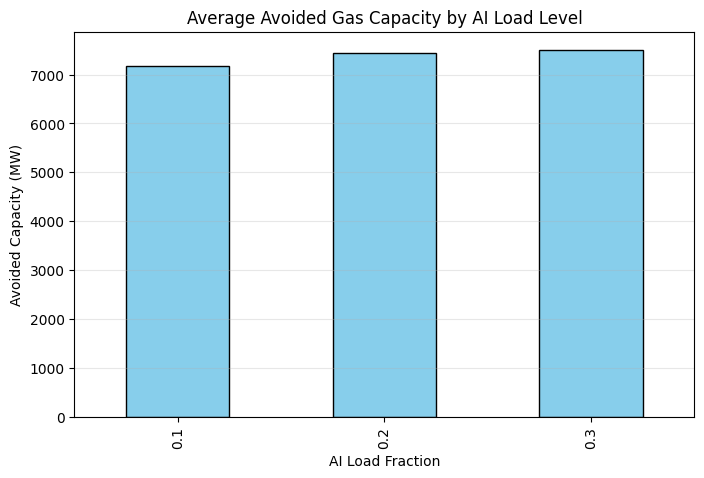

  region  ai_fraction  trial  avoided_capacity_mw  water_peak_m3h  \
0   PJME          0.1      0         14096.843027      150487.680   
1   PJME          0.2      0         14155.500215      166974.820   
2   PJME          0.3      0         14214.157403      183461.960   
3  COMED          0.1      0          4890.175627       55263.186   
4  COMED          0.2      0          4921.548579       61334.255   

   baseline_capacity_mw  baseline_water_m3h  
0          46236.033027       181464.256930  
1          53799.059215       197031.195004  
2          61362.085403       212598.133078  
3          14649.204127        68007.477338  
4          16993.709579        74078.546271  


In [ ]:
# @title 6. VISUALIZATION - *** Depricated V1 ***
# # ==========================================
# # 6. VISUALIZATION
# # ==========================================
# if not res_df.empty:
#     # Aggregated Plot
#     agg = res_df.groupby("ai_fraction")["avoided_capacity_mw"].mean()

#     plt.figure(figsize=(8, 5))
#     agg.plot(kind='bar', color='skyblue', edgecolor='black')
#     plt.title("Average Avoided Gas Capacity by AI Load Level")
#     plt.xlabel("AI Load Fraction")
#     plt.ylabel("Avoided Capacity (MW)")
#     plt.grid(axis='y', alpha=0.3)
#     plt.show()

#     print(res_df.head())
# else:
#     print("No results to plot.")